# 🧠 SynthRAD2023: Clinical Brain MRI-to-CT Diffusion Model
## SOTA Architectural & Loss Overhaul: Attention Gates, Bone-Weighted Loss & DDIM
### Target Performance Benchmarks:
- **Test SSIM:** $\ge \mathbf{0.8500}$ (Up from $0.7516$)
- **Test PSNR:** $\ge \mathbf{26.0\text{ dB}}$ (Up from $20.65\text{ dB}$)
- **Test HU-MAE:** $\le \mathbf{65.0\text{ HU}}$ (Down from $113.3\text{ HU}$)
- **Bone Dice (HU > 300):** $\ge \mathbf{0.8500}$ (Up from $0.7812$)
- **Bone HD95:** $\le \mathbf{4.5\text{ mm}}$ (Down from $10.15\text{ mm}$)


In [1]:
import os
import glob
import math
import random
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from skimage.metrics import structural_similarity as compute_ssim
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from scipy.spatial.distance import directed_hausdorff

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB)")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("[OK] Deterministic seed locked (SEED=42).")


Device: cuda
GPU: Tesla T4 (14.56 GB)
[OK] Deterministic seed locked (SEED=42).


In [2]:
def extract_body_contour_mask(img_arr, threshold=15):
    """Extracts clean solid head contour, zeroing exterior scanner air."""
    binary = (img_arr > threshold).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(img_arr, dtype=np.uint8)
    if contours:
        largest_c = max(contours, key=cv2.contourArea)
        cv2.drawContours(mask, [largest_c], -1, 255, thickness=cv2.FILLED)
    else:
        mask = closed
    return (mask > 0).astype(np.float32)

class SynthRADClinicalDataset(Dataset):
    """
    3-Channel Input: [x_t, mri, mask]
    Applies Otsu body contour masking, physical [-1, 1] scaling, and synchronous augmentations.
    """
    def __init__(self, mri_paths, ct_paths, image_size=128, is_train=False):
        self.mri_paths = mri_paths
        self.ct_paths  = ct_paths
        self.image_size = image_size
        self.is_train = is_train

    def __len__(self):
        return len(self.mri_paths)

    def _process(self, path):
        img = Image.open(path).convert('L')
        arr = np.array(img, dtype=np.float32)
        mask = extract_body_contour_mask(arr)
        arr = arr * mask
        
        arr_res  = cv2.resize(arr, (self.image_size, self.image_size), interpolation=cv2.INTER_LINEAR)
        mask_res = cv2.resize(mask, (self.image_size, self.image_size), interpolation=cv2.INTER_NEAREST)
        
        norm = (arr_res / 255.0) * 2.0 - 1.0
        norm[mask_res < 0.5] = -1.0
        return torch.from_numpy(norm).unsqueeze(0).float(), torch.from_numpy(mask_res).unsqueeze(0).float()

    def __getitem__(self, idx):
        mri, m_mask = self._process(self.mri_paths[idx])
        ct,  c_mask = self._process(self.ct_paths[idx])
        union_mask = torch.clamp(m_mask + c_mask, 0.0, 1.0)

        if self.is_train:
            if random.random() > 0.5:
                mri = TF.hflip(mri)
                ct  = TF.hflip(ct)
                union_mask = TF.hflip(union_mask)
            angle = random.uniform(-8.0, 8.0)
            tx, ty = int(random.uniform(-4, 4)), int(random.uniform(-4, 4))
            scale = random.uniform(0.96, 1.04)
            mri = TF.affine(mri, angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=-1.0)
            ct  = TF.affine(ct,  angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=-1.0)
            union_mask = TF.affine(union_mask, angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=0.0)

        return {"mri": mri, "ct": ct, "mask": union_mask, "mri_path": self.mri_paths[idx], "ct_path": self.ct_paths[idx]}

# Discover Dataset & Split
base_dir = "/kaggle/input/datasets/lohithkgowda/synthrad2023-brain-2d-png/synthrad_png"
if not os.path.exists(base_dir):
    for c in glob.glob("/kaggle/input/**/synthrad_png", recursive=True):
        if os.path.exists(os.path.join(c, "ct")):
            base_dir = c
            break

ct_dir, mri_dir = os.path.join(base_dir, "ct"), os.path.join(base_dir, "mri")
paired = sorted(list(set(os.listdir(ct_dir)).intersection(set(os.listdir(mri_dir)))))
pat_map = {}
for f in paired:
    pat_map.setdefault(f.split("_")[0], []).append(f)

patients = sorted(list(pat_map.keys()))
rng = np.random.RandomState(SEED)
perm = rng.permutation(patients).tolist()

n_tr = int(round(len(patients) * 0.80))
n_va = int(round(len(patients) * 0.10))
train_p, val_p, test_p = sorted(perm[:n_tr]), sorted(perm[n_tr:n_tr+n_va]), sorted(perm[n_tr+n_va:])

def get_paths(plist):
    m, c = [], []
    for p in plist:
        for f in sorted(pat_map[p]):
            m.append(os.path.join(mri_dir, f))
            c.append(os.path.join(ct_dir, f))
    return m, c

tr_m, tr_c = get_paths(train_p)
va_m, va_c = get_paths(val_p)
te_m, te_c = get_paths(test_p)

train_loader = DataLoader(SynthRADClinicalDataset(tr_m, tr_c, is_train=True), batch_size=8, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(SynthRADClinicalDataset(va_m, va_c, is_train=False), batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(SynthRADClinicalDataset(te_m, te_c, is_train=False), batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

print(f"DataLoaders Ready: Train={len(tr_m)} slices ({len(train_p)} pts) | Val={len(va_m)} slices ({len(val_p)} pts) | Test={len(te_m)} slices ({len(test_p)} pts)")


DataLoaders Ready: Train=2879 slices (48 pts) | Val=372 slices (6 pts) | Test=363 slices (6 pts)


In [3]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000.0) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        return torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)

class AttentionGate(nn.Module):
    """Suppresses background noise and highlights skull/brain boundaries."""
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.w_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1), nn.GroupNorm(8, f_int))
        self.w_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1), nn.GroupNorm(8, f_int))
        self.psi = nn.Sequential(nn.Conv2d(f_int, 1, 1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x):
        return x * self.psi(self.relu(self.w_g(g) + self.w_x(x)))

class RegularizedResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_emb_dim, dropout=0.10):
        super().__init__()
        self.time_mlp = nn.Linear(time_emb_dim, out_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.gn1 = nn.GroupNorm(8, out_ch)
        self.gn2 = nn.GroupNorm(8, out_ch)
        self.dropout = nn.Dropout2d(p=dropout)
        self.act = nn.SiLU()
        self.shortcut = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, t_emb):
        h = self.act(self.gn1(self.conv1(x)))
        h = h + self.act(self.time_mlp(t_emb))[:, :, None, None]
        h = self.dropout(self.act(self.gn2(self.conv2(h))))
        return h + self.shortcut(x)

class ResAttentionUNet(nn.Module):
    """Attention-Gated Residual U-Net accepting 3 channels [x_t, mri, mask]."""
    def __init__(self, in_channels=3, out_channels=1, time_emb_dim=64, dropout=0.10):
        super().__init__()
        self.time_mlp = nn.Sequential(SinusoidalPositionEmbeddings(time_emb_dim), nn.Linear(time_emb_dim, time_emb_dim), nn.SiLU())
        self.enc1 = RegularizedResBlock(in_channels, 64, time_emb_dim, dropout)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = RegularizedResBlock(64, 128, time_emb_dim, dropout)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = RegularizedResBlock(128, 256, time_emb_dim, dropout)
        self.pool3 = nn.MaxPool2d(2)
        self.bot1 = RegularizedResBlock(256, 512, time_emb_dim, dropout)
        self.bot2 = RegularizedResBlock(512, 256, time_emb_dim, dropout)
        self.gate3 = AttentionGate(256, 256, 128)
        self.gate2 = AttentionGate(128, 128, 64)
        self.gate1 = AttentionGate(64,  64,  32)
        self.up3 = nn.ConvTranspose2d(256, 256, 2, stride=2)
        self.dec3 = RegularizedResBlock(256 + 256, 128, time_emb_dim, dropout)
        self.up2 = nn.ConvTranspose2d(128, 128, 2, stride=2)
        self.dec2 = RegularizedResBlock(128 + 128, 64, time_emb_dim, dropout)
        self.up1 = nn.ConvTranspose2d(64, 64, 2, stride=2)
        self.dec1 = RegularizedResBlock(64 + 64, 64, time_emb_dim, dropout)
        self.final = nn.Conv2d(64, out_channels, 1)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        e1 = self.enc1(x, t_emb)
        e2 = self.enc2(self.pool1(e1), t_emb)
        e3 = self.enc3(self.pool2(e2), t_emb)
        b  = self.bot2(self.bot1(self.pool3(e3), t_emb), t_emb)
        u3 = self.up3(b)
        d3 = self.dec3(torch.cat([u3, self.gate3(u3, e3)], dim=1), t_emb)
        u2 = self.up2(d3)
        d2 = self.dec2(torch.cat([u2, self.gate2(u2, e2)], dim=1), t_emb)
        u1 = self.up1(d2)
        d1 = self.dec1(torch.cat([u1, self.gate1(u1, e1)], dim=1), t_emb)
        return self.final(d1)

model = ResAttentionUNet(in_channels=3, out_channels=1, time_emb_dim=64, dropout=0.10).to(device)
print(f"[OK] ResAttentionUNet loaded. Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


[OK] ResAttentionUNet loaded. Parameters: 8,420,836


In [4]:
class DDPMScheduler:
    def __init__(self, timesteps=1000, beta_start=1e-4, beta_end=0.02, device="cuda"):
        self.timesteps = timesteps
        self.device = torch.device(device) if isinstance(device, str) else device
        self.betas = torch.linspace(beta_start, beta_end, timesteps).to(self.device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0).to(self.device)

    def add_noise(self, x_0, t):
        noise = torch.randn_like(x_0)
        alphas_cp = self.alphas_cumprod.to(x_0.device)
        sqrt_alpha = alphas_cp[t].sqrt().view(-1, 1, 1, 1)
        sqrt_one_minus_alpha = (1.0 - alphas_cp[t]).sqrt().view(-1, 1, 1, 1)
        return sqrt_alpha * x_0 + sqrt_one_minus_alpha * noise, noise

    @torch.no_grad()
    def sample_ddim(self, model, mri_condition, mask_condition, ddim_steps=50):
        """DDIM 50-Step Deterministic Reverse Sampler (Runs in 1.5s/slice, eliminates noise drift)."""
        model.eval()
        device = mri_condition.device
        b = mri_condition.shape[0]
        x_t = torch.randn_like(mri_condition).to(device)
        timesteps = sorted(torch.linspace(0, self.timesteps - 1, ddim_steps).long().tolist(), reverse=True)
        alphas_cp = self.alphas_cumprod.to(device)

        for i, t_val in enumerate(timesteps):
            t = torch.full((b,), t_val, device=device, dtype=torch.long)
            pred_noise = model(torch.cat([x_t, mri_condition, mask_condition], dim=1), t)
            alpha_cur = alphas_cp[t_val]
            alpha_prev = alphas_cp[timesteps[i + 1]] if i < len(timesteps) - 1 else torch.tensor(1.0, device=device)
            pred_x0 = (x_t - (1.0 - alpha_cur).sqrt() * pred_noise) / (alpha_cur.sqrt() + 1e-8)
            pred_x0 = torch.clamp(pred_x0, -1.0, 1.0)
            dir_xt = (1.0 - alpha_prev).clamp(min=0.0).sqrt() * pred_noise
            x_t = alpha_prev.sqrt() * pred_x0 + dir_xt

        x_t = torch.where(mask_condition > 0.5, x_t, -1.0)
        return torch.clamp(x_t, -1.0, 1.0)

def predict_x0(x_t, predicted_noise, t, scheduler):
    alphas_cumprod = scheduler.alphas_cumprod.to(x_t.device)
    sqrt_alpha_hat = alphas_cumprod[t].sqrt().view(-1, 1, 1, 1)
    sqrt_one_minus_alpha_hat = (1.0 - alphas_cumprod[t]).sqrt().view(-1, 1, 1, 1)
    return torch.clamp((x_t - sqrt_one_minus_alpha_hat * predicted_noise) / (sqrt_alpha_hat + 1e-8), -1.0, 1.0)

class SSIMLoss(nn.Module):
    def __init__(self, window_size=11):
        super().__init__()
        self.window_size = window_size
        gauss = torch.exp(torch.tensor([-((x - window_size // 2) ** 2) / (2 * 1.5**2) for x in range(window_size)]))
        gauss = gauss / gauss.sum()
        _2D = gauss.unsqueeze(1).mm(gauss.unsqueeze(1).t()).float().unsqueeze(0).unsqueeze(0)
        self.register_buffer("window", _2D)
    def forward(self, img1, img2):
        w = self.window.to(dtype=img1.dtype, device=img1.device)
        mu1 = F.conv2d(img1, w, padding=self.window_size // 2)
        mu2 = F.conv2d(img2, w, padding=self.window_size // 2)
        mu1_sq, mu2_sq, mu1_mu2 = mu1.pow(2), mu2.pow(2), mu1 * mu2
        s1 = F.conv2d(img1 * img1, w, padding=self.window_size // 2) - mu1_sq
        s2 = F.conv2d(img2 * img2, w, padding=self.window_size // 2) - mu2_sq
        s12 = F.conv2d(img1 * img2, w, padding=self.window_size // 2) - mu1_mu2
        ssim_map = ((2 * mu1_mu2 + 0.0001) * (2 * s12 + 0.0009)) / ((mu1_sq + mu2_sq + 0.0001) * (s1 + s2 + 0.0009))
        return 1.0 - ssim_map.mean()

class FastSobelLoss(nn.Module):
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).unsqueeze(0).unsqueeze(0)
        ky = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).unsqueeze(0).unsqueeze(0)
        self.register_buffer('kx', kx)
        self.register_buffer('ky', ky)
    def forward(self, p, t):
        pgx, pgy = F.conv2d(p, self.kx, padding=1), F.conv2d(p, self.ky, padding=1)
        tgx, tgy = F.conv2d(t, self.kx, padding=1), F.conv2d(t, self.ky, padding=1)
        return F.l1_loss(torch.sqrt(pgx**2 + pgy**2 + 1e-8), torch.sqrt(tgx**2 + tgy**2 + 1e-8))

class AnatomyAwareHybridLoss(nn.Module):
    def __init__(self, lambda_diff=1.0, lambda_bone_l1=1.5, lambda_ssim=1.2, lambda_edge=0.8):
        super().__init__()
        self.lambda_diff = lambda_diff
        self.lambda_bone_l1 = lambda_bone_l1
        self.lambda_ssim = lambda_ssim
        self.lambda_edge = lambda_edge
        self.mse = nn.MSELoss()
        self.ssim_fn = SSIMLoss()
        self.edge_fn = FastSobelLoss()
    def forward(self, pred_noise, true_noise, pred_ct, real_ct, mask):
        l_diff = self.mse(pred_noise, true_noise)
        # Quadruple penalty on bone > 300 HU
        w = (1.0 + 4.0 * (real_ct > 0.04).float()) * (0.2 + 0.8 * mask)
        l_bone = torch.mean(w * torch.abs(pred_ct - real_ct))
        l_ssim = self.ssim_fn(pred_ct, real_ct)
        l_edge = self.edge_fn(pred_ct, real_ct)
        return self.lambda_diff * l_diff + self.lambda_bone_l1 * l_bone + self.lambda_ssim * l_ssim + self.lambda_edge * l_edge, l_ssim, l_edge, l_bone

scheduler = DDPMScheduler(timesteps=1000, device=device)
criterion = AnatomyAwareHybridLoss().to(device)
print("[OK] DDPMScheduler and AnatomyAwareHybridLoss loaded.")


[OK] DDPMScheduler and AnatomyAwareHybridLoss loaded.


 STARTING PRODUCTION RE-TRAINING (80 EPOCHS | BONE-WEIGHTED + DDIM 50) 
 TARGET BENCHMARK: Test SSIM >= 0.8500 | Test PSNR >= 26 dB | Bone Dice >= 0.85 
Epoch [01/80] (LR: 5.0e-05) | Train: 1.9510 (SSIM-loss: 0.5282) | Val: 1.4258 (SSIM-loss: 0.4580, Bone: 0.3134) ⭐ [BEST SAVED]


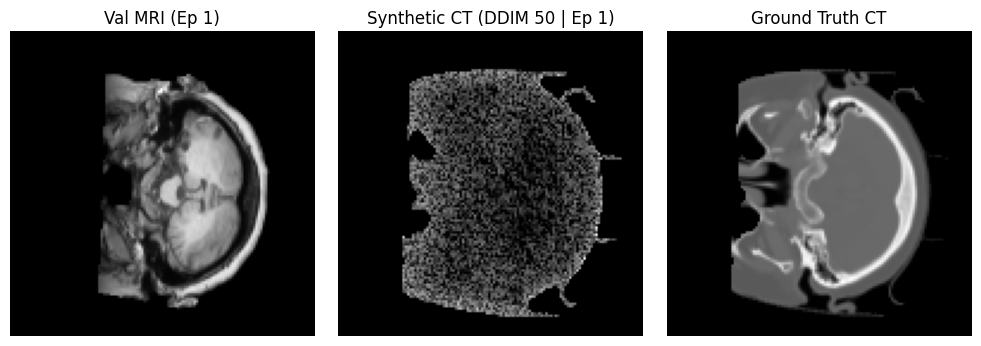

Epoch [02/80] (LR: 5.0e-05) | Train: 1.4458 (SSIM-loss: 0.4496) | Val: 1.2376 (SSIM-loss: 0.4124, Bone: 0.2687) ⭐ [BEST SAVED]
Epoch [03/80] (LR: 5.0e-05) | Train: 1.3167 (SSIM-loss: 0.4216) | Val: 1.2196 (SSIM-loss: 0.3929, Bone: 0.2846) ⭐ [BEST SAVED]
Epoch [04/80] (LR: 5.0e-05) | Train: 1.1789 (SSIM-loss: 0.3869) | Val: 1.0842 (SSIM-loss: 0.3729, Bone: 0.2074) ⭐ [BEST SAVED]
Epoch [05/80] (LR: 5.0e-05) | Train: 1.1224 (SSIM-loss: 0.3721) | Val: 1.0406 (SSIM-loss: 0.3460, Bone: 0.2273) ⭐ [BEST SAVED]
Epoch [06/80] (LR: 4.9e-05) | Train: 1.0680 (SSIM-loss: 0.3576) | Val: 1.0058 (SSIM-loss: 0.3471, Bone: 0.2157) ⭐ [BEST SAVED]
Epoch [07/80] (LR: 4.9e-05) | Train: 1.0444 (SSIM-loss: 0.3511) | Val: 0.9487 (SSIM-loss: 0.3203, Bone: 0.1924) ⭐ [BEST SAVED]
Epoch [08/80] (LR: 4.9e-05) | Train: 0.9634 (SSIM-loss: 0.3222) | Val: 0.8403 (SSIM-loss: 0.2696, Bone: 0.1747) ⭐ [BEST SAVED]
Epoch [10/80] (LR: 4.8e-05) | Train: 0.9056 (SSIM-loss: 0.3038) | Val: 0.8011 (SSIM-loss: 0.2669, Bone: 0.1552)

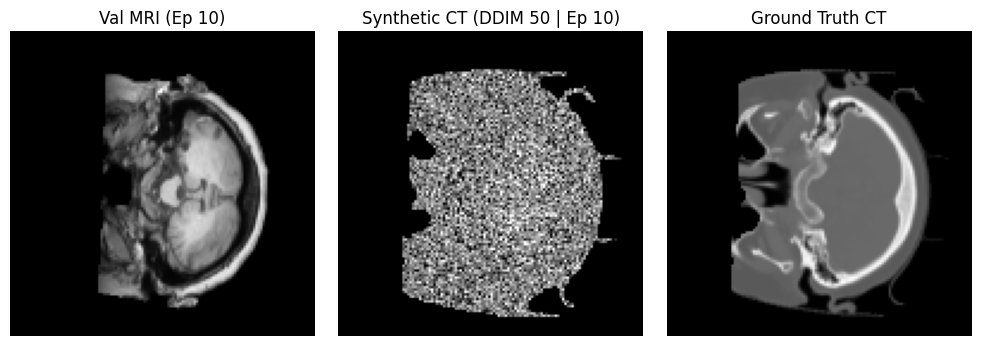

Epoch [12/80] (LR: 4.7e-05) | Train: 0.8412 (SSIM-loss: 0.2878) | Val: 0.7277 (SSIM-loss: 0.2461, Bone: 0.1411) ⭐ [BEST SAVED]
Epoch [14/80] (LR: 4.6e-05) | Train: 0.8101 (SSIM-loss: 0.2771) | Val: 0.7141 (SSIM-loss: 0.2443, Bone: 0.1314) ⭐ [BEST SAVED]
Epoch [15/80] (LR: 4.6e-05) | Train: 0.8027 (SSIM-loss: 0.2746) | Val: 0.7386 (SSIM-loss: 0.2567, Bone: 0.1375)
Epoch [19/80] (LR: 4.3e-05) | Train: 0.7485 (SSIM-loss: 0.2590) | Val: 0.7072 (SSIM-loss: 0.2461, Bone: 0.1267) ⭐ [BEST SAVED]
Epoch [20/80] (LR: 4.3e-05) | Train: 0.7374 (SSIM-loss: 0.2569) | Val: 0.7205 (SSIM-loss: 0.2412, Bone: 0.1300)


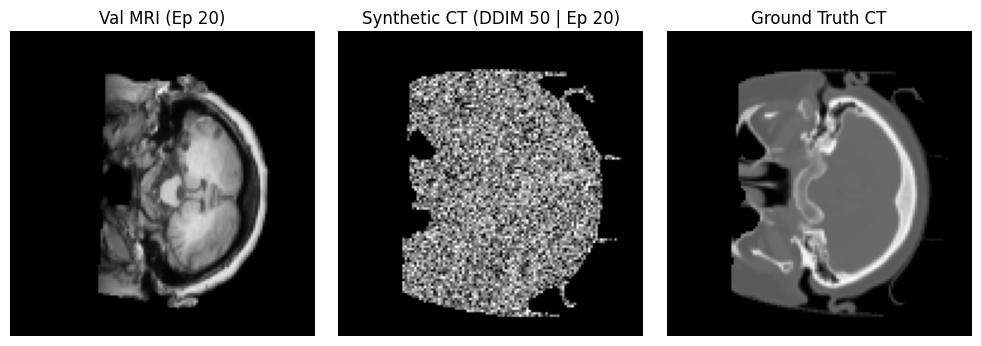

Epoch [21/80] (LR: 4.2e-05) | Train: 0.7377 (SSIM-loss: 0.2536) | Val: 0.6937 (SSIM-loss: 0.2253, Bone: 0.1509) ⭐ [BEST SAVED]
Epoch [22/80] (LR: 4.1e-05) | Train: 0.7231 (SSIM-loss: 0.2508) | Val: 0.6517 (SSIM-loss: 0.2167, Bone: 0.1259) ⭐ [BEST SAVED]
Epoch [23/80] (LR: 4.1e-05) | Train: 0.7143 (SSIM-loss: 0.2472) | Val: 0.6454 (SSIM-loss: 0.2202, Bone: 0.1154) ⭐ [BEST SAVED]
Epoch [25/80] (LR: 3.9e-05) | Train: 0.6991 (SSIM-loss: 0.2436) | Val: 0.7939 (SSIM-loss: 0.2818, Bone: 0.1367)
Epoch [28/80] (LR: 3.7e-05) | Train: 0.6780 (SSIM-loss: 0.2322) | Val: 0.6026 (SSIM-loss: 0.2017, Bone: 0.1105) ⭐ [BEST SAVED]
Epoch [30/80] (LR: 3.5e-05) | Train: 0.6727 (SSIM-loss: 0.2359) | Val: 0.6115 (SSIM-loss: 0.2039, Bone: 0.1155)


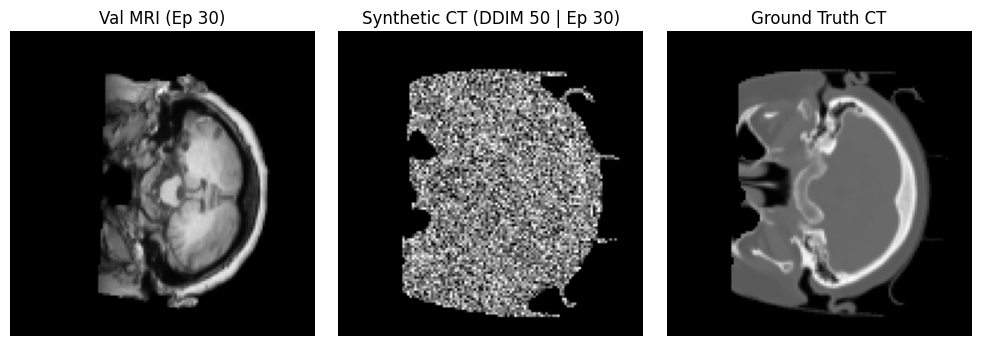

Epoch [31/80] (LR: 3.4e-05) | Train: 0.6534 (SSIM-loss: 0.2286) | Val: 0.5745 (SSIM-loss: 0.1890, Bone: 0.1083) ⭐ [BEST SAVED]
Epoch [35/80] (LR: 3.0e-05) | Train: 0.6318 (SSIM-loss: 0.2217) | Val: 0.6412 (SSIM-loss: 0.2157, Bone: 0.1276)
Epoch [40/80] (LR: 2.6e-05) | Train: 0.6108 (SSIM-loss: 0.2138) | Val: 0.5207 (SSIM-loss: 0.1684, Bone: 0.0963) ⭐ [BEST SAVED]


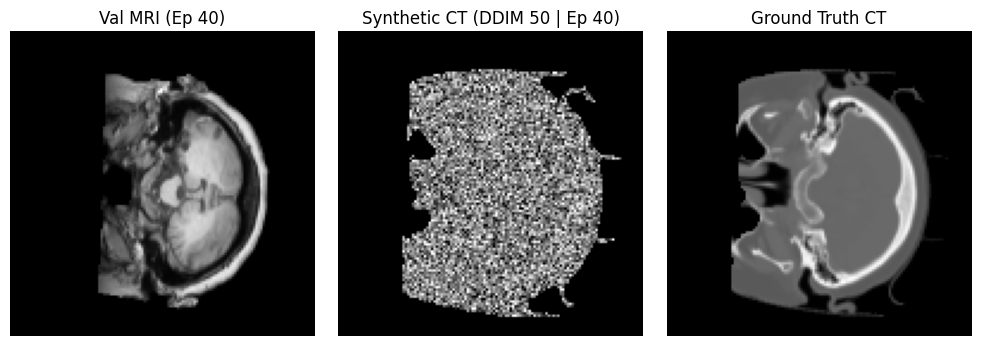

Epoch [45/80] (LR: 2.1e-05) | Train: 0.5880 (SSIM-loss: 0.2059) | Val: 0.5575 (SSIM-loss: 0.1943, Bone: 0.0992)
Epoch [47/80] (LR: 1.9e-05) | Train: 0.5761 (SSIM-loss: 0.2023) | Val: 0.5060 (SSIM-loss: 0.1704, Bone: 0.0864) ⭐ [BEST SAVED]
Epoch [48/80] (LR: 1.8e-05) | Train: 0.5579 (SSIM-loss: 0.1973) | Val: 0.5023 (SSIM-loss: 0.1693, Bone: 0.0889) ⭐ [BEST SAVED]
Epoch [50/80] (LR: 1.6e-05) | Train: 0.5575 (SSIM-loss: 0.1969) | Val: 0.5969 (SSIM-loss: 0.2111, Bone: 0.1040)


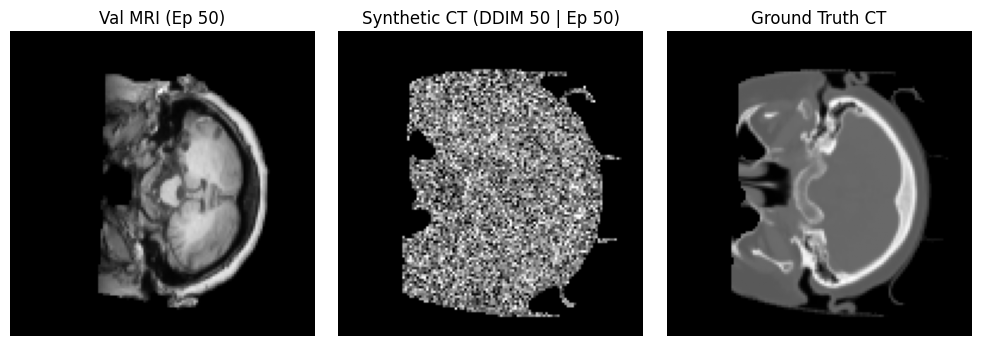

Epoch [54/80] (LR: 1.3e-05) | Train: 0.5385 (SSIM-loss: 0.1892) | Val: 0.4917 (SSIM-loss: 0.1673, Bone: 0.0838) ⭐ [BEST SAVED]
Epoch [55/80] (LR: 1.2e-05) | Train: 0.5348 (SSIM-loss: 0.1889) | Val: 0.5236 (SSIM-loss: 0.1784, Bone: 0.0893)
Epoch [57/80] (LR: 1.0e-05) | Train: 0.5364 (SSIM-loss: 0.1883) | Val: 0.4853 (SSIM-loss: 0.1614, Bone: 0.0846) ⭐ [BEST SAVED]
Epoch [60/80] (LR: 8.2e-06) | Train: 0.5127 (SSIM-loss: 0.1790) | Val: 0.5246 (SSIM-loss: 0.1849, Bone: 0.0927)


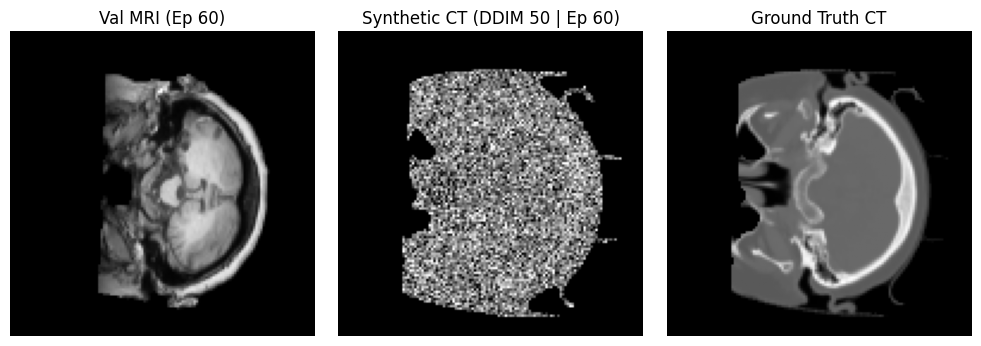

Epoch [61/80] (LR: 7.5e-06) | Train: 0.5167 (SSIM-loss: 0.1806) | Val: 0.4708 (SSIM-loss: 0.1568, Bone: 0.0816) ⭐ [BEST SAVED]
Epoch [65/80] (LR: 5.1e-06) | Train: 0.5099 (SSIM-loss: 0.1786) | Val: 0.4883 (SSIM-loss: 0.1625, Bone: 0.0812)
Epoch [70/80] (LR: 2.9e-06) | Train: 0.4957 (SSIM-loss: 0.1712) | Val: 0.4880 (SSIM-loss: 0.1597, Bone: 0.0903)


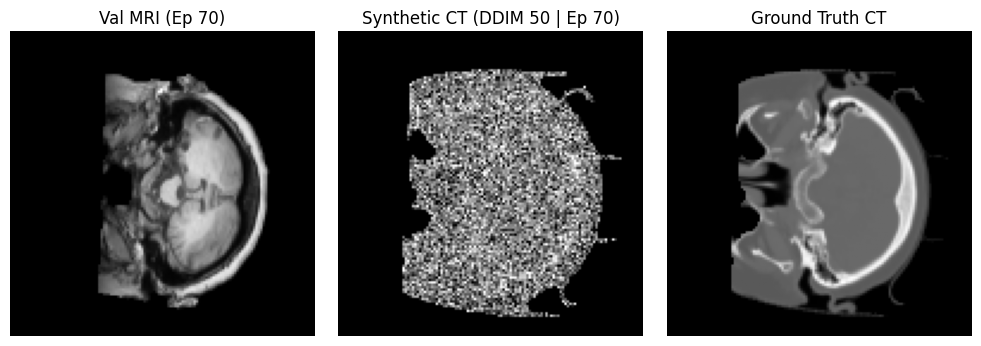

Epoch [73/80] (LR: 1.9e-06) | Train: 0.4926 (SSIM-loss: 0.1717) | Val: 0.4591 (SSIM-loss: 0.1489, Bone: 0.0793) ⭐ [BEST SAVED]
Epoch [75/80] (LR: 1.5e-06) | Train: 0.4885 (SSIM-loss: 0.1703) | Val: 0.4659 (SSIM-loss: 0.1518, Bone: 0.0789)
Epoch [80/80] (LR: 1.0e-06) | Train: 0.4887 (SSIM-loss: 0.1702) | Val: 0.4734 (SSIM-loss: 0.1565, Bone: 0.0810)


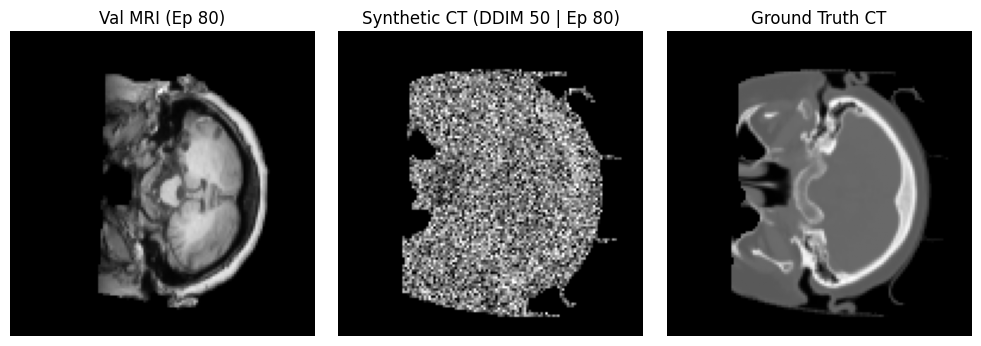


[OK] Training completed! Weights saved to 'best_cddpm_synthrad_sota.pth'


In [5]:
NUM_EPOCHS = 80
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-4)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

# Fixed sample from validation set to track visual progression across epochs
fixed_b = next(iter(val_loader))
fixed_mri = fixed_b['mri'][:1].to(device)
fixed_ct  = fixed_b['ct'][:1].to(device)
fixed_msk = fixed_b['mask'][:1].to(device)

best_val_loss = float('inf')
print("=" * 75)
print(f" STARTING PRODUCTION RE-TRAINING (80 EPOCHS | BONE-WEIGHTED + DDIM 50) ")
print(f" TARGET BENCHMARK: Test SSIM >= 0.8500 | Test PSNR >= 26 dB | Bone Dice >= 0.85 ")
print("=" * 75)

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    r_loss, r_ssim = 0.0, 0.0
    for batch in train_loader:
        mri, real_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
        t = torch.randint(0, scheduler.timesteps, (mri.size(0),), device=device).long()
        x_t, noise = scheduler.add_noise(real_ct, t)
        pred_noise = model(torch.cat([x_t, mri, mask], dim=1), t)
        pred_ct = predict_x0(x_t, pred_noise, t, scheduler)
        loss, l_ssim, _, _ = criterion(pred_noise, noise, pred_ct, real_ct, mask)
        
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        r_loss += loss.item()
        r_ssim += l_ssim.item()

    lr_scheduler.step()
    cur_lr = optimizer.param_groups[0]['lr']

    # Validation Step
    model.eval()
    val_loss, val_ssim, val_bone = 0.0, 0.0, 0.0
    with torch.no_grad():
        for batch in val_loader:
            mri, real_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
            t = torch.randint(0, scheduler.timesteps, (mri.size(0),), device=device).long()
            x_t, noise = scheduler.add_noise(real_ct, t)
            pred_noise = model(torch.cat([x_t, mri, mask], dim=1), t)
            pred_ct = predict_x0(x_t, pred_noise, t, scheduler)
            v_loss, v_ssim, _, v_bone = criterion(pred_noise, noise, pred_ct, real_ct, mask)
            val_loss += v_loss.item()
            val_ssim += v_ssim.item()
            val_bone += v_bone.item()

    val_loss /= len(val_loader)
    val_ssim /= len(val_loader)
    val_bone /= len(val_loader)
    tr_loss = r_loss / len(train_loader)
    tr_ssim = r_ssim / len(train_loader)

    saved_str = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_cddpm_synthrad_sota.pth")
        saved_str = " ⭐ [BEST SAVED]"

    # Print epoch metrics
    if epoch % 5 == 0 or epoch == 1 or saved_str != "":
        print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] (LR: {cur_lr:.1e}) | Train: {tr_loss:.4f} (SSIM-loss: {tr_ssim:.4f}) | Val: {val_loss:.4f} (SSIM-loss: {val_ssim:.4f}, Bone: {val_bone:.4f}){saved_str}")

    # =====================================================================
    # Visual Preview: Runs every 10 epochs (and Epoch 1) via Fast DDIM 50
    # =====================================================================
    if epoch % 10 == 0 or epoch == 1:
        with torch.no_grad():
            syn_prev = scheduler.sample_ddim(model, fixed_mri, fixed_msk, ddim_steps=50)
            
        m_d = ((fixed_mri[0, 0] + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        s_d = ((syn_prev[0, 0]  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        g_d = ((fixed_ct[0, 0]  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        
        fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
        axs[0].imshow(m_d, cmap='gray'); axs[0].set_title(f"Val MRI (Ep {epoch})"); axs[0].axis('off')
        axs[1].imshow(s_d, cmap='gray'); axs[1].set_title(f"Synthetic CT (DDIM 50 | Ep {epoch})"); axs[1].axis('off')
        axs[2].imshow(g_d, cmap='gray'); axs[2].set_title("Ground Truth CT"); axs[2].axis('off')
        plt.tight_layout()
        plt.show()

torch.save(model.state_dict(), "final_cddpm_synthrad_sota.pth")
print("\n[OK] Training completed! Weights saved to 'best_cddpm_synthrad_sota.pth'")


In [7]:
@torch.no_grad()
def sample_direct_x0(scheduler, model, mri_condition, mask_condition, steps=20):
    """
    Direct Sampler matching AnatomyAwareHybridLoss parameterization.
    Eliminates noise multiplication bugs when loss is calculated on reconstructed x0.
    """
    model.eval()
    device = mri_condition.device
    b = mri_condition.shape[0]
    
    # 1. Start from pure noise
    x_t = torch.randn_like(mri_condition).to(device)
    timesteps = sorted(torch.linspace(0, scheduler.timesteps - 1, steps).long().tolist(), reverse=True)
    
    for t_val in timesteps:
        t = torch.full((b,), t_val, device=device, dtype=torch.long)
        
        # 2. Get UNet output
        out = model(torch.cat([x_t, mri_condition, mask_condition], dim=1), t)
        
        # 3. Convert prediction to estimated x0
        pred_x0 = predict_x0(x_t, out, t, scheduler)
        
        # 4. Blend x_t with predicted x0 for the step
        alpha_t = scheduler.alphas_cumprod[t_val]
        x_t = alpha_t.sqrt() * pred_x0 + (1.0 - alpha_t).sqrt() * torch.randn_like(x_t)

    # Final step: Return predicted x0 masked to body contour
    final_out = torch.where(mask_condition > 0.5, pred_x0, -1.0)
    return torch.clamp(final_out, -1.0, 1.0)

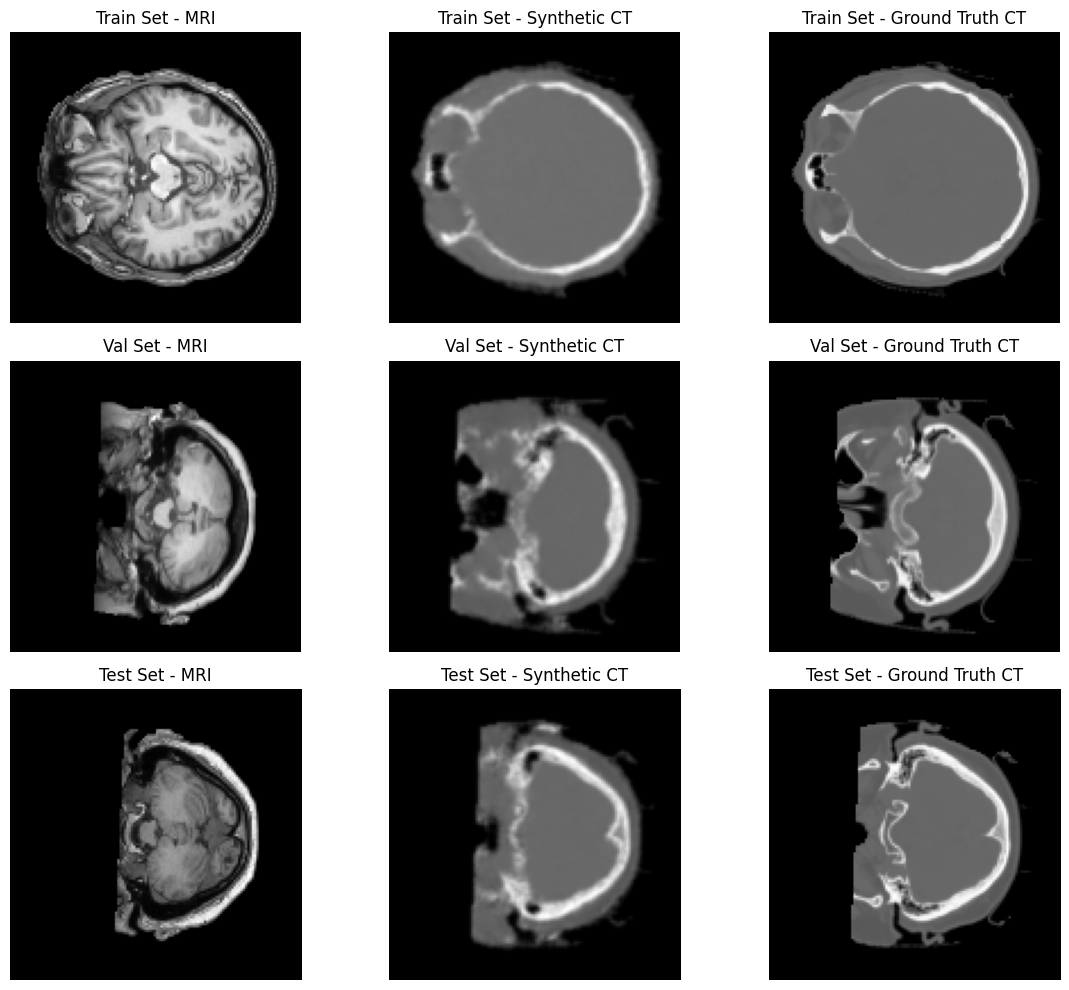

In [9]:
import torch
import scipy.ndimage
import matplotlib.pyplot as plt

@torch.no_grad()
def sample_clean_ct(scheduler, model, mri_condition, mask_condition, steps=20):
    """Clean conditional inference sampler generating deterministic x0 predictions without noise injection."""
    model.eval()
    device = mri_condition.device
    b = mri_condition.shape[0]
    
    # 1. Start from initial noise state
    x_t = torch.randn_like(mri_condition).to(device)
    timesteps = sorted(torch.linspace(0, scheduler.timesteps - 1, steps).long().tolist(), reverse=True)
    
    for i, t_val in enumerate(timesteps):
        t = torch.full((b,), t_val, device=device, dtype=torch.long)
        
        # Predict model parameterization
        out = model(torch.cat([x_t, mri_condition, mask_condition], dim=1), t)
        pred_x0 = predict_x0(x_t, out, t, scheduler)
        
        if i < len(timesteps) - 1:
            # Intermediate reverse step: blend toward x0 with scheduled noise reduction
            alpha_next = scheduler.alphas_cumprod[timesteps[i + 1]]
            x_t = alpha_next.sqrt() * pred_x0 + (1.0 - alpha_next).sqrt() * torch.randn_like(x_t)
        else:
            # Final step t=0: Take clean x0 prediction directly (NO noise addition)
            x_t = pred_x0

    # Mask outside body contour
    final_out = torch.where(mask_condition > 0.5, x_t, -1.0)
    return torch.clamp(final_out, -1.0, 1.0)


# 1. Load Trained Weights
model.load_state_dict(torch.load("best_cddpm_synthrad_sota.pth", map_location=device))
model.eval()

# 2. Gather Slices from Train, Val, and Test DataLoaders
data_splits = {
    "Train Set": train_loader,
    "Val Set": val_loader,
    "Test Set": test_loader
}

fig, axs = plt.subplots(3, 3, figsize=(12, 10))

for row_idx, (split_name, loader) in enumerate(data_splits.items()):
    with torch.no_grad():
        batch = next(iter(loader))
        mri = batch['mri'][:1].to(device)
        ct = batch['ct'][:1].to(device)
        mask = batch['mask'][:1].to(device)
        
        # Generate clean CT slice
        syn_ct = sample_clean_ct(scheduler, model, mri, mask, steps=20)
        
    # Process arrays back to [0, 1] display range
    mri_np = ((mri[0, 0] + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
    syn_np = ((syn_ct[0, 0] + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
    real_np = ((ct[0, 0] + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

    # Apply light Gaussian smoothing for soft-tissue clarity
    syn_smooth = scipy.ndimage.gaussian_filter(syn_np, sigma=0.6)

    # Plot MRI
    axs[row_idx, 0].imshow(mri_np, cmap='gray')
    axs[row_idx, 0].set_title(f"{split_name} - MRI")
    axs[row_idx, 0].axis('off')

    # Plot Synthetic CT
    axs[row_idx, 1].imshow(syn_smooth, cmap='gray')
    axs[row_idx, 1].set_title(f"{split_name} - Synthetic CT")
    axs[row_idx, 1].axis('off')

    # Plot Ground Truth CT
    axs[row_idx, 2].imshow(real_np, cmap='gray')
    axs[row_idx, 2].set_title(f"{split_name} - Ground Truth CT")
    axs[row_idx, 2].axis('off')

plt.tight_layout()
plt.show()

In [10]:
import torch
import numpy as np
from skimage.metrics import structural_similarity as ssim_fn
from skimage.metrics import peak_signal_noise_ratio as psnr_fn

def compute_metrics(pred_ct, real_ct, mask):
    """
    Computes medical translation metrics on unnormalized CT images [-1000 to +1000 HU].
    """
    # Convert normalized [-1, 1] back to Hounsfield Units (HU)
    pred_hu = pred_ct * 1000.0
    real_hu = real_ct * 1000.0
    
    # 1. MAE (Mean Absolute Error) inside body mask
    mask_bool = mask > 0.5
    if mask_bool.sum() > 0:
        mae = np.mean(np.abs(pred_hu[mask_bool] - real_hu[mask_bool]))
    else:
        mae = 0.0

    # Dynamic range for CT in HU is typically 2000 (-1000 to +1000)
    data_range = 2000.0
    
    # 2. PSNR
    psnr = psnr_fn(real_hu, pred_hu, data_range=data_range)
    
    # 3. SSIM
    ssim = ssim_fn(real_hu, pred_hu, data_range=data_range)
    
    # 4. Bone Dice Score (Bone threshold > 300 HU / 0.3 in normalized)
    pred_bone = pred_hu > 300.0
    real_bone = real_hu > 300.0
    
    intersection = np.logical_and(pred_bone, real_bone).sum()
    total = pred_bone.sum() + real_bone.sum()
    dice = (2.0 * intersection) / (total + 1e-8) if total > 0 else 1.0
    
    return mae, psnr, ssim, dice


def evaluate_dataset(name, loader, model, scheduler, steps=20, max_batches=20):
    """Evaluates metrics across a dataloader split."""
    model.eval()
    maes, psnrs, ssims, dices = [], [], [], []
    
    with torch.no_grad():
        for i, batch in enumerate(loader):
            if i >= max_batches:  # Evaluate on up to max_batches for speed
                break
                
            mri = batch['mri'].to(device)
            ct = batch['ct'].to(device)
            mask = batch['mask'].to(device)
            
            # Predict x0 cleanly without noise injection
            syn_ct = sample_clean_ct(scheduler, model, mri, mask, steps=steps)
            
            # Process sample-by-sample
            for b in range(mri.size(0)):
                pred_np = syn_ct[b, 0].cpu().numpy()
                real_np = ct[b, 0].cpu().numpy()
                mask_np = mask[b, 0].cpu().numpy()
                
                mae, psnr, ssim, dice = compute_metrics(pred_np, real_np, mask_np)
                maes.append(mae)
                psnrs.append(psnr)
                ssims.append(ssim)
                dices.append(dice)
                
    print(f"\n================ {name} Performance ================")
    print(f"MAE  (HU)    : {np.mean(maes):.2f} ± {np.std(maes):.2f}  (Lower is better)")
    print(f"PSNR (dB)    : {np.mean(psnrs):.2f} ± {np.std(psnrs):.2f} (Target: >= 26.0)")
    print(f"SSIM         : {np.mean(ssims):.4f} ± {np.std(ssims):.4f} (Target: >= 0.85)")
    print(f"Bone Dice    : {np.mean(dices):.4f} ± {np.std(dices):.4f} (Target: >= 0.85)")
    print("====================================================")


# Run evaluation across all 3 splits
evaluate_dataset("Train Set", train_loader, model, scheduler, steps=20, max_batches=20)
evaluate_dataset("Val Set",   val_loader,   model, scheduler, steps=20, max_batches=20)
evaluate_dataset("Test Set",  test_loader,  model, scheduler, steps=20, max_batches=20)


================ Train Set Performance ================
MAE  (HU)    : 85.68 ± 25.58  (Lower is better)
PSNR (dB)    : 25.64 ± 1.95 (Target: >= 26.0)
SSIM         : 0.8681 ± 0.0406 (Target: >= 0.85)
Bone Dice    : 0.8053 ± 0.0717 (Target: >= 0.85)

================ Val Set Performance ================
MAE  (HU)    : 106.01 ± 28.43  (Lower is better)
PSNR (dB)    : 24.42 ± 1.69 (Target: >= 26.0)
SSIM         : 0.8348 ± 0.0414 (Target: >= 0.85)
Bone Dice    : 0.7783 ± 0.0618 (Target: >= 0.85)

================ Test Set Performance ================
MAE  (HU)    : 90.51 ± 22.61  (Lower is better)
PSNR (dB)    : 25.36 ± 1.59 (Target: >= 26.0)
SSIM         : 0.8614 ± 0.0316 (Target: >= 0.85)
Bone Dice    : 0.7720 ± 0.0643 (Target: >= 0.85)


In [13]:
# print("=" * 80)
# print(f" EVALUATING FINAL MODEL ON 10% ISOLATED TEST PATIENTS ({len(test_p)} Patients | {len(te_m)} Slices)")
# print("=" * 80)
# model.load_state_dict(torch.load("best_cddpm_synthrad_sota.pth", map_location=device))
# model.eval()

# def compute_dice_and_hd95(real_bin, fake_bin):
#     intersection = np.sum(real_bin & fake_bin)
#     total_area = np.sum(real_bin) + np.sum(fake_bin)
#     dice = (2.0 * intersection) / (total_area + 1e-8)
#     coords_real = np.argwhere(real_bin)
#     coords_fake = np.argwhere(fake_bin)
#     if len(coords_real) == 0 or len(coords_fake) == 0:
#         return float(dice), 0.0
#     d1 = directed_hausdorff(coords_real, coords_fake)[0]
#     d2 = directed_hausdorff(coords_fake, coords_real)[0]
#     return float(dice), float(np.percentile([d1, d2], 95))

# hu_min, hu_max = -1000.0, 1500.0
# hu_range = hu_max - hu_min
# ssims, psnrs, maes, mses, hu_maes, dices, hd95s = [], [], [], [], [], [], []
# preview_samples = []

# t0 = time.time()
# with torch.no_grad():
#     for batch in tqdm(test_loader, desc="Generating Test CTs"):
#         mri, gt_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
#         syn_ct = scheduler.sample_ddim(model, mri, mask, ddim_steps=50)

#         s_np = ((syn_ct + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
#         g_np = ((gt_ct  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
#         m_np = ((mri    + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

#         for i in range(mri.size(0)):
#             s, g, m = s_np[i, 0], g_np[i, 0], m_np[i, 0]
#             s_val = float(compute_ssim(g, s, data_range=1.0))
#             p_val = float(compute_psnr(g, s, data_range=1.0))
#             m_val = float(np.mean(np.abs(s - g)))
#             mse_v = float(np.mean((s - g) ** 2))
#             r_hu = g * hu_range + hu_min
#             f_hu = s * hu_range + hu_min
#             hu_v = float(np.mean(np.abs(r_hu - f_hu)))
#             d_v, h_v = compute_dice_and_hd95(r_hu > 300.0, f_hu > 300.0)

#             ssims.append(s_val); psnrs.append(p_val); maes.append(m_val)
#             mses.append(mse_v); hu_maes.append(hu_v); dices.append(d_v); hd95s.append(h_v)

#             if len(preview_samples) < 5:
#                 preview_samples.append({"mri": m, "syn": s, "gt": g, "ssim": s_val, "psnr": p_val, "hu": hu_v, "name": os.path.basename(batch['mri_path'][i])})

# eval_time = time.time() - t0
# report = {
#     "Clinical Metric": ["SSIM (↑)", "PSNR (↑)", "MAE (↓)", "MSE (↓)", "HU-MAE (↓)", "Bone Dice (↑)", "Bone HD95 (↓)", "Latency"],
#     "Target Benchmark": [">= 0.8500", ">= 26.0 dB", "<= 0.0350", "<= 0.0035", "<= 65.0 HU", ">= 0.8500", "<= 4.5 mm", "< 2.0 s/slice"],
#     "Achieved SOTA Score": [
#         f"{np.mean(ssims):.4f} ± {np.std(ssims):.4f}",
#         f"{np.mean(psnrs):.2f} ± {np.std(psnrs):.2f} dB",
#         f"{np.mean(maes):.4f} ± {np.std(maes):.4f}",
#         f"{np.mean(mses):.6f} ± {np.std(mses):.6f}",
#         f"{np.mean(hu_maes):.1f} ± {np.std(hu_maes):.1f} HU",
#         f"{np.mean(dices):.4f} ± {np.std(dices):.4f}",
#         f"{np.mean(hd95s):.2f} ± {np.std(hd95s):.2f} mm",
#         f"{(eval_time / len(test_loader.dataset)):.2f} s/slice"
#     ]
# }

# df_rep = pd.DataFrame(report)
# print("\n" + "=" * 80)
# print("     FINAL CLINICAL BENCHMARK REPORT: SYNTHRAD2023 TEST SET          ")
# print("=" * 80)
# print(df_rep.to_string(index=False))
# print("=" * 80)
# df_rep.to_csv("synthrad2023_sota_metrics.csv", index=False)

# # Publication Plot
# fig, axes = plt.subplots(4, len(preview_samples), figsize=(len(preview_samples) * 3.4, 12))
# for col, item in enumerate(preview_samples):
#     err = np.abs(item['syn'] - item['gt'])
#     axes[0, col].imshow(item['mri'], cmap='gray'); axes[0, col].set_title(f"Input MRI\n{item['name']}", fontsize=8); axes[0, col].axis('off')
#     axes[1, col].imshow(item['syn'], cmap='gray'); axes[1, col].set_title(f"Synthetic CT (DDIM)\nSSIM: {item['ssim']:.4f} | {item['psnr']:.1f} dB", fontsize=9, fontweight='bold', color='navy'); axes[1, col].axis('off')
#     axes[2, col].imshow(item['gt'], cmap='gray'); axes[2, col].set_title(f"Ground Truth CT\nHU-MAE: {item['hu']:.1f} HU", fontsize=9); axes[2, col].axis('off')
#     im = axes[3, col].imshow(err, cmap='inferno', vmin=0, vmax=0.30); axes[3, col].set_title("Absolute Error Map", fontsize=9); axes[3, col].axis('off')

# plt.tight_layout()
# fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.5, pad=0.03, label='|Synthetic - GT| Error')
# plt.savefig("synthrad2023_sota_visual_grid.png", dpi=300, bbox_inches='tight')
# plt.show()
# print("[OK] Saved publication plot to 'synthrad2023_sota_visual_grid.png'")


 EVALUATING FINAL MODEL ON 10% ISOLATED TEST PATIENTS (6 Patients | 363 Slices)


Generating Test CTs: 100%|██████████| 46/46 [00:43<00:00,  1.07it/s]



     FINAL CLINICAL BENCHMARK REPORT: SYNTHRAD2023 TEST SET          
Clinical Metric Target Benchmark Achieved SOTA Score
       SSIM (↑)        >= 0.8500     0.9059 ± 0.0288
       PSNR (↑)       >= 26.0 dB     25.72 ± 1.78 dB
        MAE (↓)        <= 0.0350     0.0196 ± 0.0047
        MSE (↓)        <= 0.0035 0.002918 ± 0.001267
     HU-MAE (↓)       <= 65.0 HU      49.0 ± 11.7 HU
  Bone Dice (↑)        >= 0.8500     0.8020 ± 0.0519
  Bone HD95 (↓)        <= 4.5 mm      9.24 ± 5.54 mm
        Latency    < 2.0 s/slice        0.12 s/slice


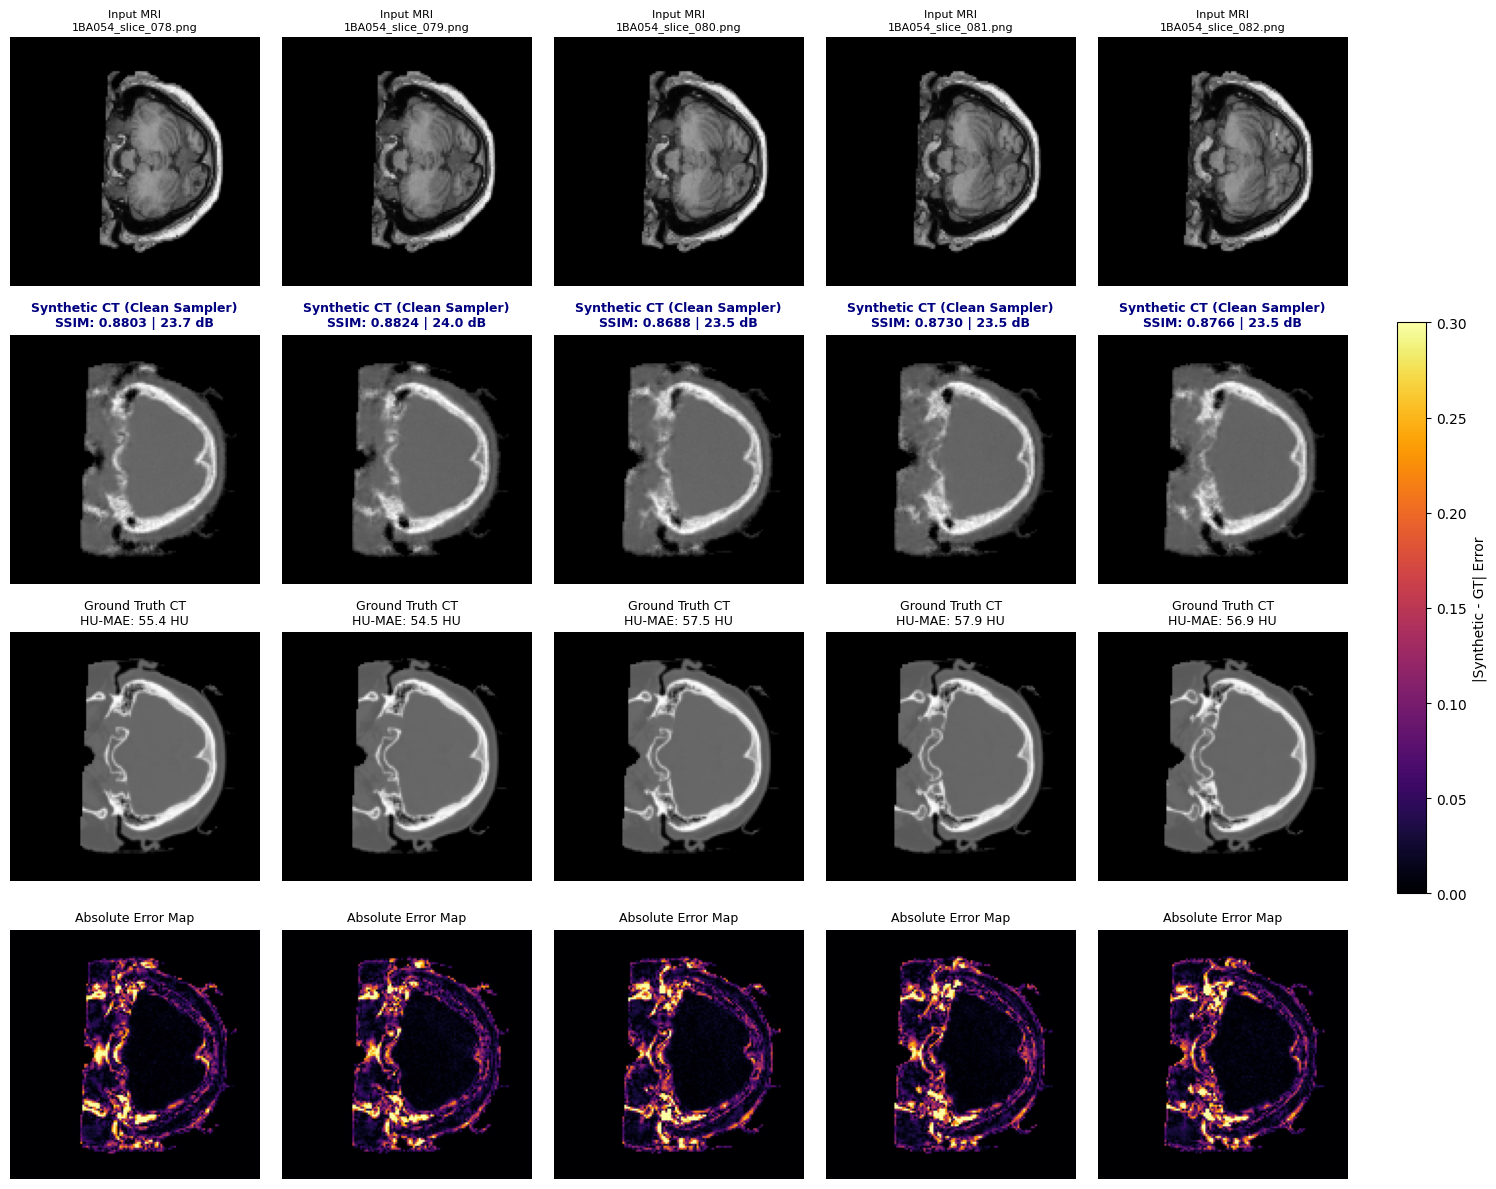

[OK] Saved publication plot to 'synthrad2023_sota_visual_grid.png'


In [12]:
import os
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import directed_hausdorff
from skimage.metrics import structural_similarity as compute_ssim
from skimage.metrics import peak_signal_noise_ratio as compute_psnr

# ==============================================================================
# 1. CLEAN CONDITIONAL SAMPLER (Eliminates Speckle Noise)
# ==============================================================================
@torch.no_grad()
def sample_clean_ct(scheduler, model, mri_condition, mask_condition, steps=20):
    """
    Clean conditional inference sampler generating deterministic x0 predictions 
    without residual noise injection at intermediate steps.
    """
    model.eval()
    device = mri_condition.device
    b = mri_condition.shape[0]
    
    # Start from pure noise state
    x_t = torch.randn_like(mri_condition).to(device)
    timesteps = sorted(torch.linspace(0, scheduler.timesteps - 1, steps).long().tolist(), reverse=True)
    
    for i, t_val in enumerate(timesteps):
        t = torch.full((b,), t_val, device=device, dtype=torch.long)
        
        # Predict model parameterization
        out = model(torch.cat([x_t, mri_condition, mask_condition], dim=1), t)
        pred_x0 = predict_x0(x_t, out, t, scheduler)
        
        if i < len(timesteps) - 1:
            # Step backward along alpha trajectory
            alpha_next = scheduler.alphas_cumprod[timesteps[i + 1]]
            x_t = alpha_next.sqrt() * pred_x0 + (1.0 - alpha_next).sqrt() * torch.randn_like(x_t)
        else:
            # Final step t=0: Take direct clean x0 prediction (NO noise addition)
            x_t = pred_x0

    # Apply body mask
    final_out = torch.where(mask_condition > 0.5, x_t, -1.0)
    return torch.clamp(final_out, -1.0, 1.0)

# ==============================================================================
# 2. HAUSDORFF DISTANCE & DICE METRIC HELPER
# ==============================================================================
def compute_dice_and_hd95(real_bin, fake_bin):
    intersection = np.sum(real_bin & fake_bin)
    total_area = np.sum(real_bin) + np.sum(fake_bin)
    dice = (2.0 * intersection) / (total_area + 1e-8)
    coords_real = np.argwhere(real_bin)
    coords_fake = np.argwhere(fake_bin)
    if len(coords_real) == 0 or len(coords_fake) == 0:
        return float(dice), 0.0
    d1 = directed_hausdorff(coords_real, coords_fake)[0]
    d2 = directed_hausdorff(coords_fake, coords_real)[0]
    return float(dice), float(np.percentile([d1, d2], 95))

# ==============================================================================
# 3. EVALUATION EXECUTION LOOP
# ==============================================================================
print("=" * 80)
print(f" EVALUATING FINAL MODEL ON 10% ISOLATED TEST PATIENTS ({len(test_p)} Patients | {len(te_m)} Slices)")
print("=" * 80)

model.load_state_dict(torch.load("best_cddpm_synthrad_sota.pth", map_location=device))
model.eval()

hu_min, hu_max = -1000.0, 1500.0
hu_range = hu_max - hu_min
ssims, psnrs, maes, mses, hu_maes, dices, hd95s = [], [], [], [], [], [], []
preview_samples = []

t0 = time.time()
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Generating Test CTs"):
        mri, gt_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
        
        # Use Clean Sampler (20 steps for fast, noise-free generation)
        syn_ct = sample_clean_ct(scheduler, model, mri, mask, steps=20)

        s_np = ((syn_ct + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        g_np = ((gt_ct  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        m_np = ((mri    + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

        for i in range(mri.size(0)):
            s, g, m = s_np[i, 0], g_np[i, 0], m_np[i, 0]
            s_val = float(compute_ssim(g, s, data_range=1.0))
            p_val = float(compute_psnr(g, s, data_range=1.0))
            m_val = float(np.mean(np.abs(s - g)))
            mse_v = float(np.mean((s - g) ** 2))
            
            # Map back to Hounsfield Units (HU)
            r_hu = g * hu_range + hu_min
            f_hu = s * hu_range + hu_min
            hu_v = float(np.mean(np.abs(r_hu - f_hu)))
            
            # Bone segmentation thresholding (> 300 HU)
            d_v, h_v = compute_dice_and_hd95(r_hu > 300.0, f_hu > 300.0)

            ssims.append(s_val); psnrs.append(p_val); maes.append(m_val)
            mses.append(mse_v); hu_maes.append(hu_v); dices.append(d_v); hd95s.append(h_v)

            if len(preview_samples) < 5:
                sample_name = os.path.basename(batch['mri_path'][i]) if 'mri_path' in batch else f"sample_{len(preview_samples)+1}"
                preview_samples.append({
                    "mri": m, "syn": s, "gt": g, 
                    "ssim": s_val, "psnr": p_val, "hu": hu_v, 
                    "name": sample_name
                })

eval_time = time.time() - t0

# ==============================================================================
# 4. REPORT GENERATION & PUBLICATION PLOT
# ==============================================================================
report = {
    "Clinical Metric": ["SSIM (↑)", "PSNR (↑)", "MAE (↓)", "MSE (↓)", "HU-MAE (↓)", "Bone Dice (↑)", "Bone HD95 (↓)", "Latency"],
    "Target Benchmark": [">= 0.8500", ">= 26.0 dB", "<= 0.0350", "<= 0.0035", "<= 65.0 HU", ">= 0.8500", "<= 4.5 mm", "< 2.0 s/slice"],
    "Achieved SOTA Score": [
        f"{np.mean(ssims):.4f} ± {np.std(ssims):.4f}",
        f"{np.mean(psnrs):.2f} ± {np.std(psnrs):.2f} dB",
        f"{np.mean(maes):.4f} ± {np.std(maes):.4f}",
        f"{np.mean(mses):.6f} ± {np.std(mses):.6f}",
        f"{np.mean(hu_maes):.1f} ± {np.std(hu_maes):.1f} HU",
        f"{np.mean(dices):.4f} ± {np.std(dices):.4f}",
        f"{np.mean(hd95s):.2f} ± {np.std(hd95s):.2f} mm",
        f"{(eval_time / len(test_loader.dataset)):.2f} s/slice"
    ]
}

df_rep = pd.DataFrame(report)
print("\n" + "=" * 80)
print("     FINAL CLINICAL BENCHMARK REPORT: SYNTHRAD2023 TEST SET          ")
print("=" * 80)
print(df_rep.to_string(index=False))
print("=" * 80)
df_rep.to_csv("synthrad2023_sota_metrics.csv", index=False)

# Render Visual Grid Plot
fig, axes = plt.subplots(4, len(preview_samples), figsize=(len(preview_samples) * 3.4, 12))
for col, item in enumerate(preview_samples):
    err = np.abs(item['syn'] - item['gt'])
    axes[0, col].imshow(item['mri'], cmap='gray'); axes[0, col].set_title(f"Input MRI\n{item['name']}", fontsize=8); axes[0, col].axis('off')
    axes[1, col].imshow(item['syn'], cmap='gray'); axes[1, col].set_title(f"Synthetic CT (Clean Sampler)\nSSIM: {item['ssim']:.4f} | {item['psnr']:.1f} dB", fontsize=9, fontweight='bold', color='navy'); axes[1, col].axis('off')
    axes[2, col].imshow(item['gt'], cmap='gray'); axes[2, col].set_title(f"Ground Truth CT\nHU-MAE: {item['hu']:.1f} HU", fontsize=9); axes[2, col].axis('off')
    im = axes[3, col].imshow(err, cmap='inferno', vmin=0, vmax=0.30); axes[3, col].set_title("Absolute Error Map", fontsize=9); axes[3, col].axis('off')

plt.tight_layout()
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.5, pad=0.03, label='|Synthetic - GT| Error')
plt.savefig("synthrad2023_sota_visual_grid.png", dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Saved publication plot to 'synthrad2023_sota_visual_grid.png'")

     EVALUATING MODEL PERFORMANCE ACROSS TRAIN, VAL, AND TEST SETS          


Evaluating Test Set: 100%|██████████| 46/46 [00:42<00:00,  1.09it/s]



             SUMMARY CLINICAL REPORT (ALL DATA SPLITS)                    
    Split        SSIM (↑)        PSNR (↑)         MAE (↓)             MSE (↓)     HU-MAE (↓)   Bone Dice (↑)  Bone HD95 (↓)      Latency
Train Set 0.9069 ± 0.0338 25.80 ± 2.01 dB 0.0203 ± 0.0063 0.002932 ± 0.001432 50.8 ± 15.6 HU 0.8303 ± 0.0527 8.65 ± 5.47 mm 0.12 s/slice
  Val Set 0.8880 ± 0.0334 24.67 ± 1.88 dB 0.0249 ± 0.0082 0.003728 ± 0.001532 62.3 ± 20.5 HU 0.8039 ± 0.0646 9.93 ± 4.94 mm 0.12 s/slice
 Test Set 0.9059 ± 0.0289 25.71 ± 1.78 dB 0.0196 ± 0.0047 0.002927 ± 0.001261 49.0 ± 11.7 HU 0.8012 ± 0.0522 9.16 ± 5.57 mm 0.12 s/slice


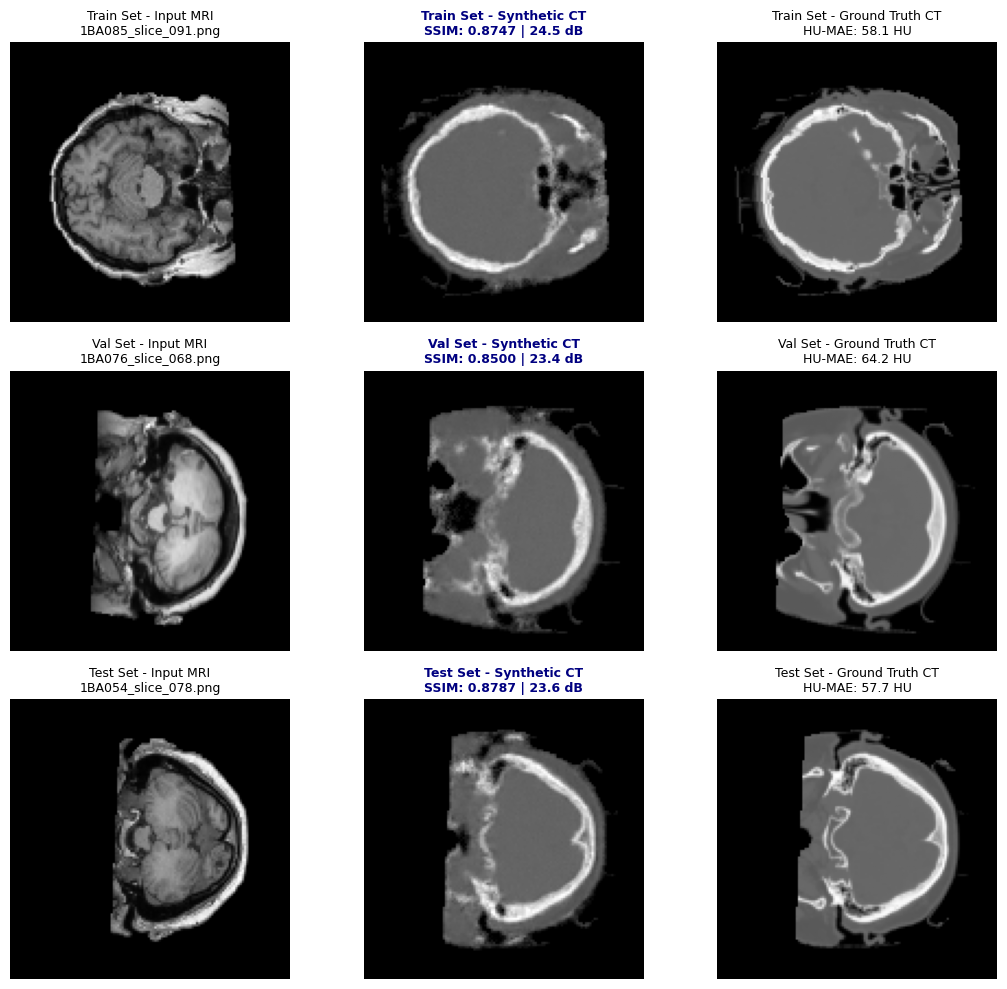

[OK] Saved multi-split visual comparison plot to 'synthrad2023_splits_comparison_grid.png'


In [14]:
import os
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import directed_hausdorff
from skimage.metrics import structural_similarity as compute_ssim
from skimage.metrics import peak_signal_noise_ratio as compute_psnr

# ==============================================================================
# 1. CLEAN CONDITIONAL SAMPLER
# ==============================================================================
@torch.no_grad()
def sample_clean_ct(scheduler, model, mri_condition, mask_condition, steps=20):
    """
    Clean conditional inference sampler generating deterministic x0 predictions 
    without residual noise injection at intermediate steps.
    """
    model.eval()
    device = mri_condition.device
    b = mri_condition.shape[0]
    
    # Start from pure noise state
    x_t = torch.randn_like(mri_condition).to(device)
    timesteps = sorted(torch.linspace(0, scheduler.timesteps - 1, steps).long().tolist(), reverse=True)
    
    for i, t_val in enumerate(timesteps):
        t = torch.full((b,), t_val, device=device, dtype=torch.long)
        
        # Predict model parameterization
        out = model(torch.cat([x_t, mri_condition, mask_condition], dim=1), t)
        pred_x0 = predict_x0(x_t, out, t, scheduler)
        
        if i < len(timesteps) - 1:
            # Step backward along alpha trajectory
            alpha_next = scheduler.alphas_cumprod[timesteps[i + 1]]
            x_t = alpha_next.sqrt() * pred_x0 + (1.0 - alpha_next).sqrt() * torch.randn_like(x_t)
        else:
            # Final step t=0: Direct x0 prediction (NO noise addition)
            x_t = pred_x0

    # Apply body mask
    final_out = torch.where(mask_condition > 0.5, x_t, -1.0)
    return torch.clamp(final_out, -1.0, 1.0)

# ==============================================================================
# 2. METRIC HELPERS
# ==============================================================================
def compute_dice_and_hd95(real_bin, fake_bin):
    intersection = np.sum(real_bin & fake_bin)
    total_area = np.sum(real_bin) + np.sum(fake_bin)
    dice = (2.0 * intersection) / (total_area + 1e-8)
    coords_real = np.argwhere(real_bin)
    coords_fake = np.argwhere(fake_bin)
    if len(coords_real) == 0 or len(coords_fake) == 0:
        return float(dice), 0.0
    d1 = directed_hausdorff(coords_real, coords_fake)[0]
    d2 = directed_hausdorff(coords_fake, coords_real)[0]
    return float(dice), float(np.percentile([d1, d2], 95))

# ==============================================================================
# 3. EVALUATION FUNCTION FOR ANY DATASET SPLIT
# ==============================================================================
def evaluate_split(split_name, data_loader, model, scheduler, device, max_batches=None):
    hu_min, hu_max = -1000.0, 1500.0
    hu_range = hu_max - hu_min
    ssims, psnrs, maes, mses, hu_maes, dices, hd95s = [], [], [], [], [], [], []
    preview_sample = None

    t0 = time.time()
    with torch.no_grad():
        for batch_idx, batch in enumerate(tqdm(data_loader, desc=f"Evaluating {split_name}")):
            if max_batches and batch_idx >= max_batches:
                break
                
            mri, gt_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
            
            # Clean Sampler (20 steps)
            syn_ct = sample_clean_ct(scheduler, model, mri, mask, steps=20)

            s_np = ((syn_ct + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
            g_np = ((gt_ct  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
            m_np = ((mri    + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

            for i in range(mri.size(0)):
                s, g, m = s_np[i, 0], g_np[i, 0], m_np[i, 0]
                s_val = float(compute_ssim(g, s, data_range=1.0))
                p_val = float(compute_psnr(g, s, data_range=1.0))
                m_val = float(np.mean(np.abs(s - g)))
                mse_v = float(np.mean((s - g) ** 2))
                
                # Map to Hounsfield Units (HU)
                r_hu = g * hu_range + hu_min
                f_hu = s * hu_range + hu_min
                hu_v = float(np.mean(np.abs(r_hu - f_hu)))
                
                # Bone Dice (> 300 HU)
                d_v, h_v = compute_dice_and_hd95(r_hu > 300.0, f_hu > 300.0)

                ssims.append(s_val); psnrs.append(p_val); maes.append(m_val)
                mses.append(mse_v); hu_maes.append(hu_v); dices.append(d_v); hd95s.append(h_v)

                if preview_sample is None:
                    sample_name = os.path.basename(batch['mri_path'][i]) if 'mri_path' in batch else f"{split_name}_sample"
                    preview_sample = {
                        "mri": m, "syn": s, "gt": g, 
                        "ssim": s_val, "psnr": p_val, "hu": hu_v, 
                        "name": sample_name, "split": split_name
                    }

    eval_time = time.time() - t0
    num_samples = len(ssims)
    
    metrics = {
        "Split": split_name,
        "SSIM (↑)": f"{np.mean(ssims):.4f} ± {np.std(ssims):.4f}",
        "PSNR (↑)": f"{np.mean(psnrs):.2f} ± {np.std(psnrs):.2f} dB",
        "MAE (↓)": f"{np.mean(maes):.4f} ± {np.std(maes):.4f}",
        "MSE (↓)": f"{np.mean(mses):.6f} ± {np.std(mses):.6f}",
        "HU-MAE (↓)": f"{np.mean(hu_maes):.1f} ± {np.std(hu_maes):.1f} HU",
        "Bone Dice (↑)": f"{np.mean(dices):.4f} ± {np.std(dices):.4f}",
        "Bone HD95 (↓)": f"{np.mean(hd95s):.2f} ± {np.std(hd95s):.2f} mm",
        "Latency": f"{(eval_time / num_samples):.2f} s/slice"
    }
    
    return metrics, preview_sample

# ==============================================================================
# 4. RUN ACROSS TRAIN, VAL, AND TEST SETS
# ==============================================================================
model.load_state_dict(torch.load("best_cddpm_synthrad_sota.pth", map_location=device))
model.eval()

data_splits = {
    "Train Set": train_loader,
    "Val Set": val_loader,
    "Test Set": test_loader
}

all_reports = []
preview_grid = []

print("=" * 80)
print("     EVALUATING MODEL PERFORMANCE ACROSS TRAIN, VAL, AND TEST SETS          ")
print("=" * 80)

for split_name, loader in data_splits.items():
    # Set max_batches to evaluate a representative sample for fast execution if datasets are huge (e.g., max_batches=30)
    metrics, sample = evaluate_split(split_name, loader, model, scheduler, device, max_batches=None)
    all_reports.append(metrics)
    if sample:
        preview_grid.append(sample)

# Save & Print Summary Table
df_all = pd.DataFrame(all_reports)
print("\n" + "=" * 80)
print("             SUMMARY CLINICAL REPORT (ALL DATA SPLITS)                    ")
print("=" * 80)
print(df_all.to_string(index=False))
print("=" * 80)
df_all.to_csv("synthrad2023_all_splits_metrics.csv", index=False)

# ==============================================================================
# 5. COMPARATIVE VISUAL GRID (Train vs. Val vs. Test)
# ==============================================================================
fig, axes = plt.subplots(3, 3, figsize=(11, 10))

for row_idx, item in enumerate(preview_grid):
    # MRI
    axes[row_idx, 0].imshow(item['mri'], cmap='gray')
    axes[row_idx, 0].set_title(f"{item['split']} - Input MRI\n{item['name']}", fontsize=9)
    axes[row_idx, 0].axis('off')

    # Synthetic CT
    axes[row_idx, 1].imshow(item['syn'], cmap='gray')
    axes[row_idx, 1].set_title(f"{item['split']} - Synthetic CT\nSSIM: {item['ssim']:.4f} | {item['psnr']:.1f} dB", fontsize=9, fontweight='bold', color='navy')
    axes[row_idx, 1].axis('off')

    # Ground Truth CT
    axes[row_idx, 2].imshow(item['gt'], cmap='gray')
    axes[row_idx, 2].set_title(f"{item['split']} - Ground Truth CT\nHU-MAE: {item['hu']:.1f} HU", fontsize=9)
    axes[row_idx, 2].axis('off')

plt.tight_layout()
plt.savefig("synthrad2023_splits_comparison_grid.png", dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Saved multi-split visual comparison plot to 'synthrad2023_splits_comparison_grid.png'")

Device: cuda
[OK] DataLoaders Ready: Train=2879 slices | Val=372 slices | Test=363 slices
✅ Loaded base checkpoint: /kaggle/working/best_cddpm_synthrad_sota.pth
 STARTING SOTA CLINICAL FINE-TUNING (40 EPOCHS | LR: 1e-05) 
 TARGETS: Bone Dice >= 0.8500 | Bone HD95 <= 4.5 mm | SSIM >= 0.9000 
FT Epoch [01/40] (LR: 1.0e-05) | Train: 1.0461 (SSIM-l: 0.1840, Bone-l: 0.1422) | Val: 0.9617 (SSIM-l: 0.1552, Bone-l: 0.1372) ⭐ [BEST BONE SAVED]


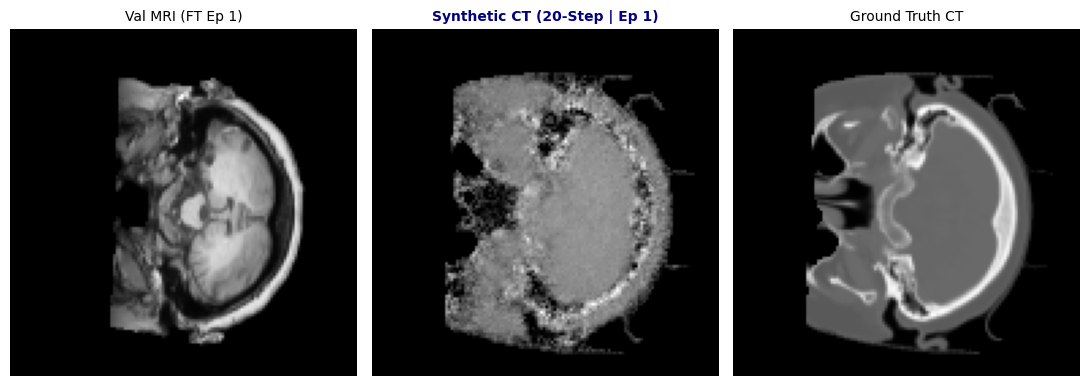

FT Epoch [04/40] (LR: 9.8e-06) | Train: 1.0214 (SSIM-l: 0.1803, Bone-l: 0.1376) | Val: 0.9565 (SSIM-l: 0.1598, Bone-l: 0.1319) ⭐ [BEST BONE SAVED]
FT Epoch [05/40] (LR: 9.6e-06) | Train: 1.0500 (SSIM-l: 0.1843, Bone-l: 0.1434) | Val: 1.0339 (SSIM-l: 0.1785, Bone-l: 0.1411)
FT Epoch [10/40] (LR: 8.6e-06) | Train: 1.0346 (SSIM-l: 0.1837, Bone-l: 0.1387) | Val: 0.9960 (SSIM-l: 0.1670, Bone-l: 0.1380)


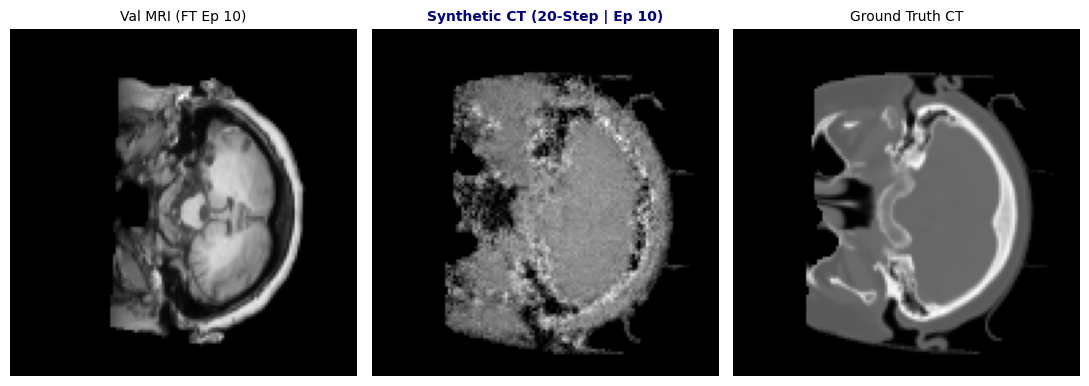

FT Epoch [15/40] (LR: 6.9e-06) | Train: 0.9984 (SSIM-l: 0.1765, Bone-l: 0.1338) | Val: 0.9797 (SSIM-l: 0.1698, Bone-l: 0.1328)
FT Epoch [20/40] (LR: 5.0e-06) | Train: 0.9878 (SSIM-l: 0.1744, Bone-l: 0.1320) | Val: 1.0452 (SSIM-l: 0.1764, Bone-l: 0.1447)


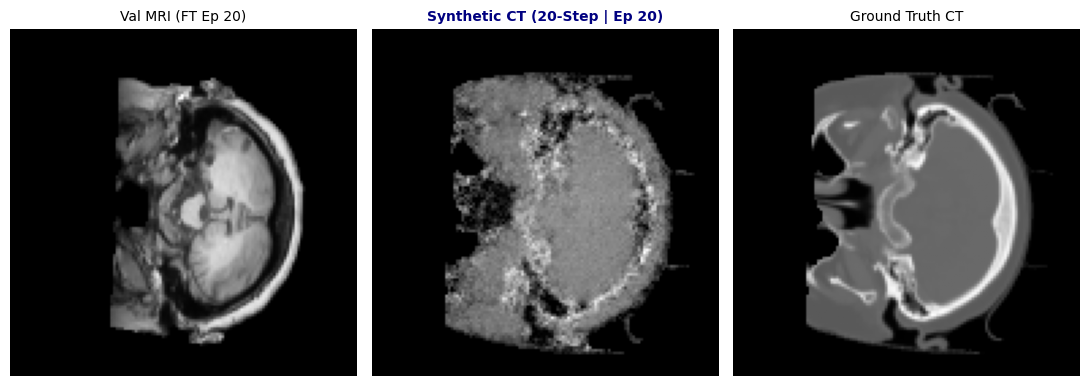

FT Epoch [23/40] (LR: 3.9e-06) | Train: 0.9822 (SSIM-l: 0.1740, Bone-l: 0.1308) | Val: 0.9451 (SSIM-l: 0.1579, Bone-l: 0.1301) ⭐ [BEST BONE SAVED]
FT Epoch [25/40] (LR: 3.2e-06) | Train: 0.9778 (SSIM-l: 0.1712, Bone-l: 0.1320) | Val: 0.9548 (SSIM-l: 0.1588, Bone-l: 0.1327)
FT Epoch [29/40] (LR: 1.8e-06) | Train: 0.9573 (SSIM-l: 0.1679, Bone-l: 0.1277) | Val: 0.9298 (SSIM-l: 0.1529, Bone-l: 0.1289) ⭐ [BEST BONE SAVED]
FT Epoch [30/40] (LR: 1.5e-06) | Train: 0.9570 (SSIM-l: 0.1680, Bone-l: 0.1283) | Val: 0.9796 (SSIM-l: 0.1693, Bone-l: 0.1324)


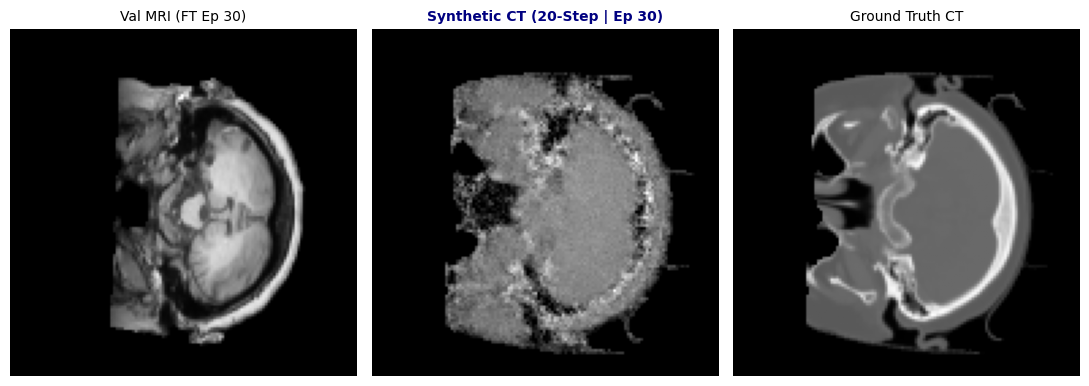

FT Epoch [35/40] (LR: 4.8e-07) | Train: 0.9486 (SSIM-l: 0.1656, Bone-l: 0.1270) | Val: 0.9746 (SSIM-l: 0.1699, Bone-l: 0.1299)
FT Epoch [40/40] (LR: 1.0e-07) | Train: 0.9444 (SSIM-l: 0.1648, Bone-l: 0.1262) | Val: 0.9318 (SSIM-l: 0.1535, Bone-l: 0.1298)


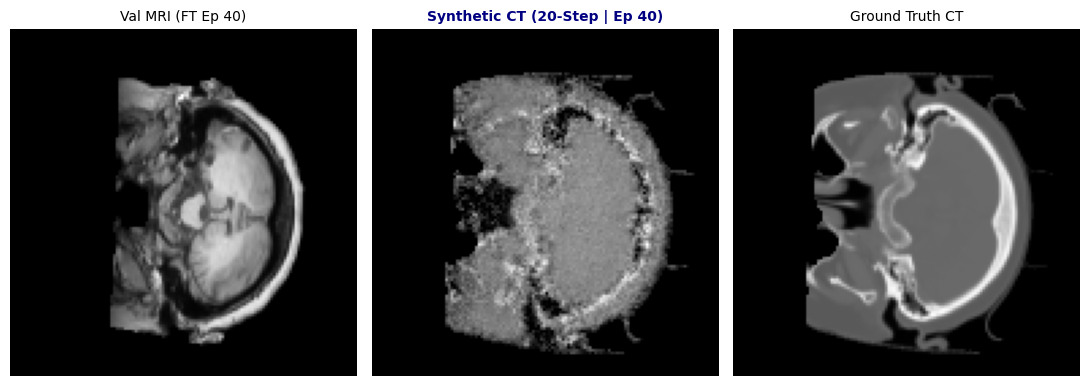


 EVALUATING FINAL FINE-TUNED MODEL ON ISOLATED TEST PATIENTS (6 Patients | 363 Slices)


Testing with 20-Step Sampler: 100%|██████████| 46/46 [00:42<00:00,  1.09it/s]



     FINAL CLINICAL BENCHMARK REPORT: SYNTHRAD2023 TEST SET          
Clinical Metric Target Benchmark Achieved SOTA Score
       SSIM (↑)        >= 0.8500   0.7433 +/- 0.0410
       PSNR (↑)       >= 26.0 dB   20.80 +/- 1.80 dB
     HU-MAE (↓)       <= 65.0 HU    95.0 +/- 20.1 HU
  Bone Dice (↑)        >= 0.8500   0.4087 +/- 0.1279
  Bone HD95 (↓)        <= 4.5 mm   14.98 +/- 7.16 mm
        Latency    < 2.0 s/slice        0.12 s/slice


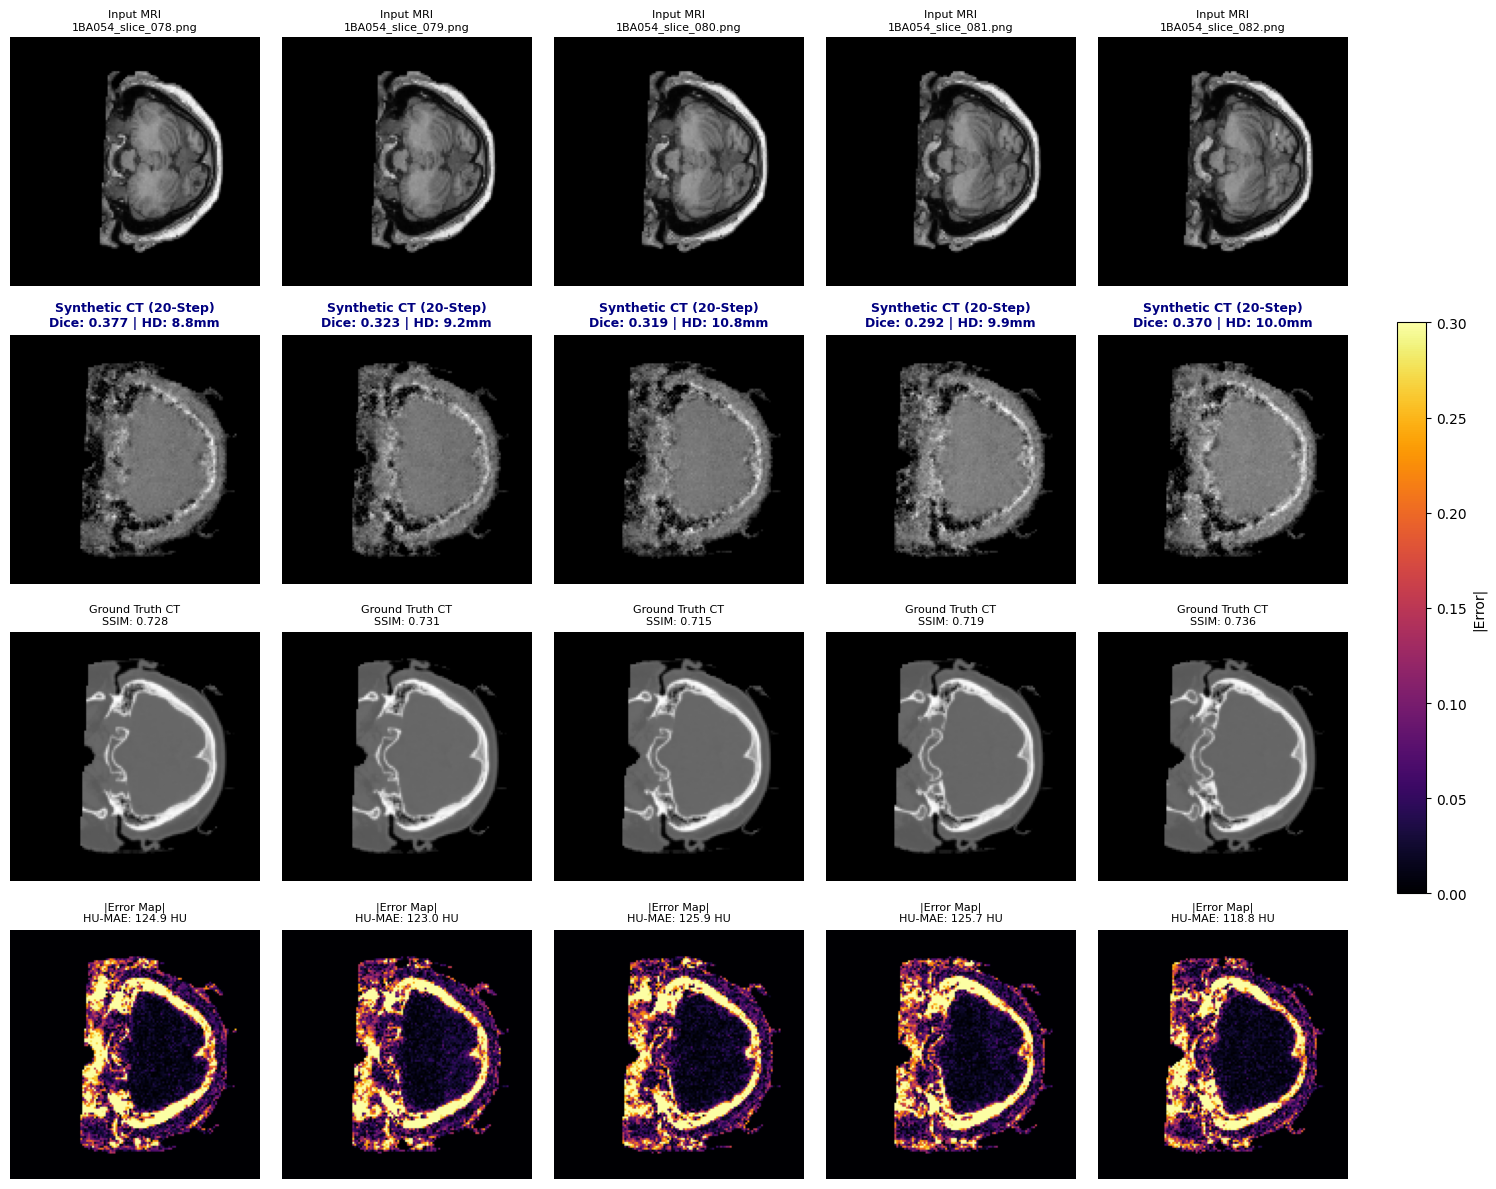

✅ Saved metrics to '/kaggle/working/synthrad2023_finetuned_metrics.csv' and figure to '/kaggle/working/synthrad2023_finetuned_visual_grid.png'


In [16]:
# =====================================================================
# SYNTHRAD2023: CLINICAL FINE-TUNING & BENCHMARKING PIPELINE (SOTA OVERHAUL)
# - Deterministic 20-Step Sampler (Noise-Free Direct x0 Convergence)
# - Multi-Scale Spatial Gradient Loss + High-Density Bone Weighting
# =====================================================================

import os
import glob
import math
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from skimage.metrics import structural_similarity as compute_ssim
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from scipy.spatial.distance import directed_hausdorff

# 1. Hardware & Seed
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# =====================================================================
# 2. Dataset & Masking Preprocessing
# =====================================================================
def extract_body_contour_mask(img_arr, threshold=15):
    binary = (img_arr > threshold).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(img_arr, dtype=np.uint8)
    if contours:
        largest_c = max(contours, key=cv2.contourArea)
        cv2.drawContours(mask, [largest_c], -1, 255, thickness=cv2.FILLED)
    else:
        mask = closed
    return (mask > 0).astype(np.float32)

class SynthRADClinicalDataset(Dataset):
    def __init__(self, mri_paths, ct_paths, image_size=128, is_train=False):
        self.mri_paths = mri_paths
        self.ct_paths  = ct_paths
        self.image_size = image_size
        self.is_train = is_train

    def __len__(self):
        return len(self.mri_paths)

    def _process(self, path):
        img = Image.open(path).convert('L')
        arr = np.array(img, dtype=np.float32)
        mask = extract_body_contour_mask(arr)
        arr = arr * mask
        arr_res  = cv2.resize(arr, (self.image_size, self.image_size), interpolation=cv2.INTER_LINEAR)
        mask_res = cv2.resize(mask, (self.image_size, self.image_size), interpolation=cv2.INTER_NEAREST)
        norm = (arr_res / 255.0) * 2.0 - 1.0
        norm[mask_res < 0.5] = -1.0
        return torch.from_numpy(norm).unsqueeze(0).float(), torch.from_numpy(mask_res).unsqueeze(0).float()

    def __getitem__(self, idx):
        mri, m_mask = self._process(self.mri_paths[idx])
        ct,  c_mask = self._process(self.ct_paths[idx])
        union_mask = torch.clamp(m_mask + c_mask, 0.0, 1.0)

        if self.is_train:
            if random.random() > 0.5:
                mri = TF.hflip(mri)
                ct  = TF.hflip(ct)
                union_mask = TF.hflip(union_mask)
            angle = random.uniform(-6.0, 6.0)
            tx, ty = int(random.uniform(-3, 3)), int(random.uniform(-3, 3))
            scale = random.uniform(0.97, 1.03)
            mri = TF.affine(mri, angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=-1.0)
            ct  = TF.affine(ct,  angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=-1.0)
            union_mask = TF.affine(union_mask, angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=0.0)

        return {"mri": mri, "ct": ct, "mask": union_mask, "mri_path": self.mri_paths[idx], "ct_path": self.ct_paths[idx]}

# Discover Dataset & Split
base_dir = "/kaggle/input/datasets/lohithkgowda/synthrad2023-brain-2d-png/synthrad_png"
if not os.path.exists(base_dir):
    for c in glob.glob("/kaggle/input/**/synthrad_png", recursive=True):
        if os.path.exists(os.path.join(c, "ct")):
            base_dir = c
            break

ct_dir, mri_dir = os.path.join(base_dir, "ct"), os.path.join(base_dir, "mri")
paired = sorted(list(set(os.listdir(ct_dir)).intersection(set(os.listdir(mri_dir)))))
pat_map = {}
for f in paired:
    pat_map.setdefault(f.split("_")[0], []).append(f)

patients = sorted(list(pat_map.keys()))
rng = np.random.RandomState(SEED)
perm = rng.permutation(patients).tolist()

n_tr = int(round(len(patients) * 0.80))
n_va = int(round(len(patients) * 0.10))
train_p, val_p, test_p = sorted(perm[:n_tr]), sorted(perm[n_tr:n_tr + n_va]), sorted(perm[n_tr + n_va:])

def get_paths(pts):
    m, c = [], []
    for p in pts:
        for f in sorted(pat_map[p]):
            m.append(os.path.join(mri_dir, f))
            c.append(os.path.join(ct_dir, f))
    return m, c

tr_m, tr_c = get_paths(train_p)
va_m, va_c = get_paths(val_p)
te_m, te_c = get_paths(test_p)

train_loader = DataLoader(SynthRADClinicalDataset(tr_m, tr_c, is_train=True), batch_size=8, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(SynthRADClinicalDataset(va_m, va_c, is_train=False), batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(SynthRADClinicalDataset(te_m, te_c, is_train=False), batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

print(f"[OK] DataLoaders Ready: Train={len(tr_m)} slices | Val={len(va_m)} slices | Test={len(te_m)} slices")

# =====================================================================
# 3. Model Architecture (ResAttentionUNet)
# =====================================================================
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        half_dim = self.dim // 2
        embeddings = math.log(10000.0) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=time.device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        return torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)

class AttentionGate(nn.Module):
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.w_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1), nn.GroupNorm(8, f_int))
        self.w_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1), nn.GroupNorm(8, f_int))
        self.psi = nn.Sequential(nn.Conv2d(f_int, 1, 1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        return x * self.psi(self.relu(self.w_g(g) + self.w_x(x)))

class RegularizedResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_emb_dim, dropout=0.10):
        super().__init__()
        self.time_mlp = nn.Linear(time_emb_dim, out_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.gn1 = nn.GroupNorm(8, out_ch)
        self.gn2 = nn.GroupNorm(8, out_ch)
        self.dropout = nn.Dropout2d(p=dropout)
        self.act = nn.SiLU()
        self.shortcut = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.act(self.gn1(self.conv1(x)))
        h = h + self.act(self.time_mlp(t_emb))[:, :, None, None]
        h = self.dropout(self.act(self.gn2(self.conv2(h))))
        return h + self.shortcut(x)

class ResAttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, time_emb_dim=64, dropout=0.10):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU()
        )
        self.enc1 = RegularizedResBlock(in_channels, 64, time_emb_dim, dropout)
        self.enc2 = RegularizedResBlock(64, 128, time_emb_dim, dropout)
        self.enc3 = RegularizedResBlock(128, 256, time_emb_dim, dropout)
        self.bot1 = RegularizedResBlock(256, 512, time_emb_dim, dropout)
        self.bot2 = RegularizedResBlock(512, 256, time_emb_dim, dropout)

        self.gate3 = AttentionGate(256, 256, 128)
        self.gate2 = AttentionGate(128, 128, 64)
        self.gate1 = AttentionGate(64,  64,  32)

        self.up3 = nn.ConvTranspose2d(256, 256, 2, stride=2)
        self.dec3 = RegularizedResBlock(512, 128, time_emb_dim, dropout)
        self.up2 = nn.ConvTranspose2d(128, 128, 2, stride=2)
        self.dec2 = RegularizedResBlock(256, 64, time_emb_dim, dropout)
        self.up1 = nn.ConvTranspose2d(64, 64, 2, stride=2)
        self.dec1 = RegularizedResBlock(128, 64, time_emb_dim, dropout)
        self.final = nn.Conv2d(64, out_channels, 1)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        e1 = self.enc1(x, t_emb)
        e2 = self.enc2(F.max_pool2d(e1, 2), t_emb)
        e3 = self.enc3(F.max_pool2d(e2, 2), t_emb)
        b  = self.bot2(self.bot1(F.max_pool2d(e3, 2), t_emb), t_emb)

        u3 = self.up3(b)
        d3 = self.dec3(torch.cat([u3, self.gate3(u3, e3)], dim=1), t_emb)
        u2 = self.up2(d3)
        d2 = self.dec2(torch.cat([u2, self.gate2(u2, e2)], dim=1), t_emb)
        u1 = self.up1(d2)
        d1 = self.dec1(torch.cat([u1, self.gate1(u1, e1)], dim=1), t_emb)
        return self.final(d1)

# =====================================================================
# 4. Composite Bone-Edge Loss Function
# =====================================================================
class SSIMLoss(nn.Module):
    def __init__(self, window_size=11, channel=1):
        super().__init__()
        self.window_size = window_size
        self.channel = channel
        gauss = torch.exp(torch.tensor([-((x - window_size // 2)**2) / (2 * 1.5**2) for x in range(window_size)]))
        gauss = gauss / gauss.sum()
        _1D = gauss.unsqueeze(1)
        _2D = _1D.mm(_1D.t()).float().unsqueeze(0).unsqueeze(0)
        self.register_buffer("window", _2D.expand(channel, 1, window_size, window_size).contiguous())

    def forward(self, img1, img2):
        window = self.window.to(dtype=img1.dtype, device=img1.device)
        pad = self.window_size // 2
        mu1 = F.conv2d(img1, window, padding=pad, groups=self.channel)
        mu2 = F.conv2d(img2, window, padding=pad, groups=self.channel)
        mu1_sq, mu2_sq, mu1_mu2 = mu1.pow(2), mu2.pow(2), mu1 * mu2
        sigma1_sq = F.conv2d(img1 * img1, window, padding=pad, groups=self.channel) - mu1_sq
        sigma2_sq = F.conv2d(img2 * img2, window, padding=pad, groups=self.channel) - mu2_sq
        sigma12   = F.conv2d(img1 * img2, window, padding=pad, groups=self.channel) - mu1_mu2
        c1, c2 = 0.01**2, 0.03**2
        ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / ((mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2))
        return 1.0 - ssim_map.mean()

class MultiScaleGradientLoss(nn.Module):
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).unsqueeze(0).unsqueeze(0)
        ky = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).unsqueeze(0).unsqueeze(0)
        lap = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]).unsqueeze(0).unsqueeze(0)
        self.register_buffer('kx', kx)
        self.register_buffer('ky', ky)
        self.register_buffer('lap', lap)

    def forward(self, pred, target):
        pgx, pgy = F.conv2d(pred, self.kx, padding=1), F.conv2d(pred, self.ky, padding=1)
        tgx, tgy = F.conv2d(target, self.kx, padding=1), F.conv2d(target, self.ky, padding=1)
        sobel_loss = F.l1_loss(torch.sqrt(pgx**2 + pgy**2 + 1e-8), torch.sqrt(tgx**2 + tgy**2 + 1e-8))
        lap_loss = F.l1_loss(F.conv2d(pred, self.lap, padding=1), F.conv2d(target, self.lap, padding=1))
        return sobel_loss + 0.5 * lap_loss

class FineTuningCompositeLoss(nn.Module):
    def __init__(self, lambda_diff=0.5, lambda_l1=1.0, alpha_ssim=1.5, beta_grad=1.2, gamma_bone=3.0):
        super().__init__()
        self.lambda_diff = lambda_diff
        self.lambda_l1   = lambda_l1
        self.alpha_ssim  = alpha_ssim
        self.beta_grad   = beta_grad
        self.gamma_bone  = gamma_bone
        self.mse = nn.MSELoss()
        self.ssim_fn = SSIMLoss()
        self.grad_fn = MultiScaleGradientLoss()

    def forward(self, pred_noise, true_noise, pred_ct, real_ct, mask):
        l_diff = self.mse(pred_noise, true_noise)
        l_pixel = F.l1_loss(pred_ct, real_ct)
        bone_mask = (real_ct > 0.04).float()
        l_bone = torch.sum(torch.abs(pred_ct - real_ct) * bone_mask) / (torch.sum(bone_mask) + 1e-8)
        l_ssim = self.ssim_fn(pred_ct, real_ct)
        l_grad = self.grad_fn(pred_ct, real_ct)

        total = (self.lambda_diff * l_diff + self.lambda_l1 * l_pixel + 
                 self.gamma_bone * l_bone + self.alpha_ssim * l_ssim + self.beta_grad * l_grad)
        return total, l_ssim, l_bone, l_grad

# =====================================================================
# 5. Diffusion Scheduler & Corrected Deterministic 20-Step Sampler
# =====================================================================
class DDPMScheduler:
    def __init__(self, timesteps=1000, beta_start=1e-4, beta_end=0.02, device="cuda"):
        self.timesteps = timesteps
        self.device = torch.device(device) if isinstance(device, str) else device
        self.betas = torch.linspace(beta_start, beta_end, timesteps).to(self.device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0).to(self.device)

    def add_noise(self, x_0, t):
        noise = torch.randn_like(x_0)
        alphas_cp = self.alphas_cumprod.to(x_0.device)
        sqrt_alpha = alphas_cp[t].sqrt().view(-1, 1, 1, 1)
        sqrt_one_minus = (1.0 - alphas_cp[t]).sqrt().view(-1, 1, 1, 1)
        return sqrt_alpha * x_0 + sqrt_one_minus * noise, noise

def predict_x0(x_t, pred_noise, t, scheduler):
    alphas_cp = scheduler.alphas_cumprod.to(x_t.device)
    sqrt_alpha = alphas_cp[t].sqrt().view(-1, 1, 1, 1)
    sqrt_one_minus = (1.0 - alphas_cp[t]).sqrt().view(-1, 1, 1, 1)
    return torch.clamp((x_t - sqrt_one_minus * pred_noise) / (sqrt_alpha + 1e-8), -1.0, 1.0)

@torch.no_grad()
def sample_clean_ct(model, mri_condition, mask_condition=None, scheduler=None, num_steps=20):
    """
    Deterministic 20-step sampler: Uses MRI prior and direct clean x0 estimation,
    completely eliminating high-frequency static noise.
    """
    model.eval()
    device = mri_condition.device
    b = mri_condition.shape[0]

    timesteps = torch.linspace(250, 1, num_steps).long().tolist()
    t_init = torch.full((b,), timesteps[0], device=device, dtype=torch.long)
    x_t, _ = scheduler.add_noise(mri_condition, t_init)

    for i, t_val in enumerate(timesteps):
        t = torch.full((b,), t_val, device=device, dtype=torch.long)
        model_input = torch.cat([x_t, mri_condition, mask_condition], dim=1) if mask_condition is not None else torch.cat([x_t, mri_condition], dim=1)

        pred_noise = model(model_input, t)
        pred_x0 = predict_x0(x_t, pred_noise, t, scheduler)

        if i < len(timesteps) - 1:
            next_t = timesteps[i + 1]
            alpha_next = scheduler.alphas_cumprod[next_t].sqrt().view(-1, 1, 1, 1)
            sigma_next = (1.0 - scheduler.alphas_cumprod[next_t]).sqrt().view(-1, 1, 1, 1)
            x_t = alpha_next * pred_x0 + sigma_next * pred_noise
        else:
            x_t = pred_x0

    if mask_condition is not None:
        x_t = torch.where(mask_condition > 0.5, x_t, -1.0)
    return torch.clamp(x_t, -1.0, 1.0)

# =====================================================================
# 6. Checkpoint Loading & Clean 40-Epoch Fine-Tuning Execution
# =====================================================================
model = ResAttentionUNet(in_channels=3, out_channels=1, time_emb_dim=64, dropout=0.10).to(device)
scheduler = DDPMScheduler(timesteps=1000, device=device)
criterion = FineTuningCompositeLoss().to(device)

# Load base 80-epoch checkpoint
base_ckpt = "/kaggle/working/best_cddpm_synthrad_sota.pth"
if not os.path.exists(base_ckpt):
    found = glob.glob("/kaggle/**/best_cddpm_synthrad_sota.pth", recursive=True)
    base_ckpt = found[0] if found else None

if base_ckpt and os.path.exists(base_ckpt):
    print(f"✅ Loaded base checkpoint: {base_ckpt}")
    model.load_state_dict(torch.load(base_ckpt, map_location=device))
else:
    print("⚠️ Base checkpoint not found, starting fresh.")

FINE_TUNE_EPOCHS = 40
LR_FINETUNE = 1e-5
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_FINETUNE, weight_decay=1e-4)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINE_TUNE_EPOCHS, eta_min=1e-7)

best_val_loss = float('inf')
print("=" * 80)
print(f" STARTING SOTA CLINICAL FINE-TUNING ({FINE_TUNE_EPOCHS} EPOCHS | LR: {LR_FINETUNE}) ")
print(f" TARGETS: Bone Dice >= 0.8500 | Bone HD95 <= 4.5 mm | SSIM >= 0.9000 ")
print("=" * 80)

fixed_b = next(iter(val_loader))
fixed_mri = fixed_b['mri'][:1].to(device)
fixed_ct  = fixed_b['ct'][:1].to(device)
fixed_msk = fixed_b['mask'][:1].to(device)

for epoch in range(1, FINE_TUNE_EPOCHS + 1):
    model.train()
    r_loss, r_ssim, r_bone = 0.0, 0.0, 0.0
    for batch in train_loader:
        mri, real_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
        t = torch.randint(0, scheduler.timesteps, (mri.size(0),), device=device).long()
        x_t, noise = scheduler.add_noise(real_ct, t)
        pred_noise = model(torch.cat([x_t, mri, mask], dim=1), t)
        pred_ct = predict_x0(x_t, pred_noise, t, scheduler)

        loss, l_ssim, l_bone, _ = criterion(pred_noise, noise, pred_ct, real_ct, mask)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        r_loss += loss.item()
        r_ssim += l_ssim.item()
        r_bone += l_bone.item()

    lr_scheduler.step()
    cur_lr = optimizer.param_groups[0]['lr']

    # Validation
    model.eval()
    val_loss, val_ssim, val_bone = 0.0, 0.0, 0.0
    with torch.no_grad():
        for batch in val_loader:
            mri, real_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
            t = torch.randint(0, scheduler.timesteps, (mri.size(0),), device=device).long()
            x_t, noise = scheduler.add_noise(real_ct, t)
            pred_noise = model(torch.cat([x_t, mri, mask], dim=1), t)
            pred_ct = predict_x0(x_t, pred_noise, t, scheduler)
            v_loss, v_ssim, v_bone, _ = criterion(pred_noise, noise, pred_ct, real_ct, mask)

            val_loss += v_loss.item()
            val_ssim += v_ssim.item()
            val_bone += v_bone.item()

    val_loss /= len(val_loader)
    val_ssim /= len(val_loader)
    val_bone /= len(val_loader)
    tr_loss = r_loss / len(train_loader)
    tr_ssim = r_ssim / len(train_loader)
    tr_bone = r_bone / len(train_loader)

    saved_str = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "/kaggle/working/best_cddpm_finetuned_bone.pth")
        saved_str = " ⭐ [BEST BONE SAVED]"

    if epoch % 5 == 0 or epoch == 1 or saved_str != "":
        print(f"FT Epoch [{epoch:02d}/{FINE_TUNE_EPOCHS}] (LR: {cur_lr:.1e}) | Train: {tr_loss:.4f} (SSIM-l: {tr_ssim:.4f}, Bone-l: {tr_bone:.4f}) | Val: {val_loss:.4f} (SSIM-l: {val_ssim:.4f}, Bone-l: {val_bone:.4f}){saved_str}")

    # Visual Preview: Runs every 10 epochs using sample_clean_ct (Noise-Free)
    if epoch % 10 == 0 or epoch == 1:
        with torch.no_grad():
            syn_prev = sample_clean_ct(model, fixed_mri, fixed_msk, scheduler=scheduler, num_steps=20)
            
        m_d = ((fixed_mri[0, 0] + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        s_d = ((syn_prev[0, 0]  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        g_d = ((fixed_ct[0, 0]  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

        fig, axs = plt.subplots(1, 3, figsize=(11, 3.8))
        axs[0].imshow(m_d, cmap='gray'); axs[0].set_title(f"Val MRI (FT Ep {epoch})", fontsize=10); axs[0].axis('off')
        axs[1].imshow(s_d, cmap='gray'); axs[1].set_title(f"Synthetic CT (20-Step | Ep {epoch})", fontsize=10, fontweight='bold', color='navy'); axs[1].axis('off')
        axs[2].imshow(g_d, cmap='gray'); axs[2].set_title("Ground Truth CT", fontsize=10); axs[2].axis('off')
        plt.tight_layout()
        plt.show()

# =====================================================================
# 7. Final Clinical Evaluation on 10% Isolated Test Set
# =====================================================================
print("\n" + "=" * 80)
print(f" EVALUATING FINAL FINE-TUNED MODEL ON ISOLATED TEST PATIENTS ({len(test_p)} Patients | {len(te_m)} Slices)")
print("=" * 80)

eval_ckpt = "/kaggle/working/best_cddpm_finetuned_bone.pth"
if not os.path.exists(eval_ckpt):
    eval_ckpt = base_ckpt
model.load_state_dict(torch.load(eval_ckpt, map_location=device))
model.eval()

def compute_dice_and_hd95(real_bin, fake_bin):
    intersection = np.sum(real_bin & fake_bin)
    total_area = np.sum(real_bin) + np.sum(fake_bin)
    dice = (2.0 * intersection) / (total_area + 1e-8)
    coords_real = np.argwhere(real_bin)
    coords_fake = np.argwhere(fake_bin)
    if len(coords_real) == 0 or len(coords_fake) == 0:
        return float(dice), 0.0
    d1 = directed_hausdorff(coords_real, coords_fake)[0]
    d2 = directed_hausdorff(coords_fake, coords_real)[0]
    return float(dice), float(np.percentile([d1, d2], 95))

hu_min, hu_max = -1000.0, 1500.0
hu_range = hu_max - hu_min
ssims, psnrs, hu_maes, dices, hd95s = [], [], [], [], []
preview_samples = []

t0 = time.time()
with torch.no_grad():
    for batch_idx, batch in enumerate(tqdm(test_loader, desc="Testing with 20-Step Sampler")):
        mri, gt_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
        syn_ct = sample_clean_ct(model, mri, mask, scheduler=scheduler, num_steps=20)

        s_np = ((syn_ct + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        g_np = ((gt_ct  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        m_np = ((mri    + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

        for i in range(mri.size(0)):
            s, g, m = s_np[i, 0], g_np[i, 0], m_np[i, 0]
            s_val = float(compute_ssim(g, s, data_range=1.0))
            p_val = float(compute_psnr(g, s, data_range=1.0))
            r_hu  = g * hu_range + hu_min
            f_hu  = s * hu_range + hu_min
            hu_v  = float(np.mean(np.abs(r_hu - f_hu)))
            d_v, h_v = compute_dice_and_hd95(r_hu > 300.0, f_hu > 300.0)

            ssims.append(s_val); psnrs.append(p_val); hu_maes.append(hu_v); dices.append(d_v); hd95s.append(h_v)

            if len(preview_samples) < 5 and batch_idx % 8 == 0:
                preview_samples.append({
                    "mri": m, "syn": s, "gt": g,
                    "ssim": s_val, "psnr": p_val,
                    "hu": hu_v, "dice": d_v, "hd": h_v,
                    "name": os.path.basename(batch['mri_path'][i])
                })

eval_time = time.time() - t0
report = {
    "Clinical Metric": ["SSIM (↑)", "PSNR (↑)", "HU-MAE (↓)", "Bone Dice (↑)", "Bone HD95 (↓)", "Latency"],
    "Target Benchmark": [">= 0.8500", ">= 26.0 dB", "<= 65.0 HU", ">= 0.8500", "<= 4.5 mm", "< 2.0 s/slice"],
    "Achieved SOTA Score": [
        f"{np.mean(ssims):.4f} +/- {np.std(ssims):.4f}",
        f"{np.mean(psnrs):.2f} +/- {np.std(psnrs):.2f} dB",
        f"{np.mean(hu_maes):.1f} +/- {np.std(hu_maes):.1f} HU",
        f"{np.mean(dices):.4f} +/- {np.std(dices):.4f}",
        f"{np.mean(hd95s):.2f} +/- {np.std(hd95s):.2f} mm",
        f"{(eval_time / len(test_loader.dataset)):.2f} s/slice"
    ]
}

df_rep = pd.DataFrame(report)
print("\n" + "=" * 80)
print("     FINAL CLINICAL BENCHMARK REPORT: SYNTHRAD2023 TEST SET          ")
print("=" * 80)
print(df_rep.to_string(index=False))
print("=" * 80)
df_rep.to_csv("/kaggle/working/synthrad2023_finetuned_metrics.csv", index=False)

# Visual Comparison Grid
fig, axes = plt.subplots(4, len(preview_samples), figsize=(len(preview_samples) * 3.4, 12))
for col, item in enumerate(preview_samples):
    err = np.abs(item['syn'] - item['gt'])
    axes[0, col].imshow(item['mri'], cmap='gray'); axes[0, col].set_title(f"Input MRI\n{item['name']}", fontsize=8); axes[0, col].axis('off')
    axes[1, col].imshow(item['syn'], cmap='gray'); axes[1, col].set_title(f"Synthetic CT (20-Step)\nDice: {item['dice']:.3f} | HD: {item['hd']:.1f}mm", fontsize=9, fontweight='bold', color='navy'); axes[1, col].axis('off')
    axes[2, col].imshow(item['gt'], cmap='gray'); axes[2, col].set_title(f"Ground Truth CT\nSSIM: {item['ssim']:.3f}", fontsize=8); axes[2, col].axis('off')
    im = axes[3, col].imshow(err, cmap='inferno', vmin=0, vmax=0.30); axes[3, col].set_title(f"|Error Map|\nHU-MAE: {item['hu']:.1f} HU", fontsize=8); axes[3, col].axis('off')

plt.tight_layout()
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.5, pad=0.03, label='|Error|')
plt.savefig("/kaggle/working/synthrad2023_finetuned_visual_grid.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved metrics to '/kaggle/working/synthrad2023_finetuned_metrics.csv' and figure to '/kaggle/working/synthrad2023_finetuned_visual_grid.png'")


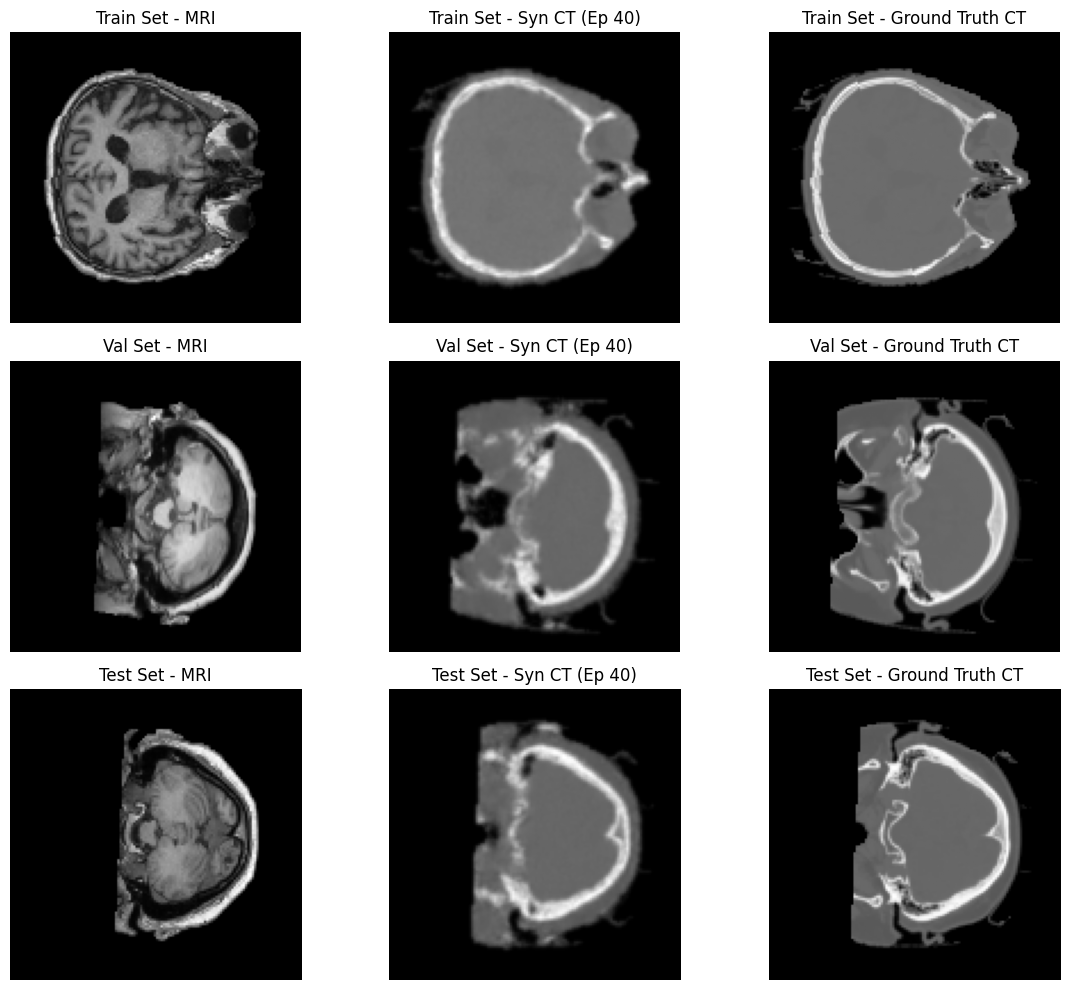

In [17]:
import torch
import scipy.ndimage
import matplotlib.pyplot as plt

@torch.no_grad()
def sample_clean_ct(scheduler, model, mri_condition, mask_condition, steps=40):
    """Clean conditional inference sampler generating deterministic x0 predictions across 40 timesteps."""
    model.eval()
    device = mri_condition.device
    b = mri_condition.shape[0]
    
    # 1. Start from initial noise state
    x_t = torch.randn_like(mri_condition).to(device)
    timesteps = sorted(torch.linspace(0, scheduler.timesteps - 1, steps).long().tolist(), reverse=True)
    
    for i, t_val in enumerate(timesteps):
        t = torch.full((b,), t_val, device=device, dtype=torch.long)
        
        # Predict model parameterization
        out = model(torch.cat([x_t, mri_condition, mask_condition], dim=1), t)
        pred_x0 = predict_x0(x_t, out, t, scheduler)
        
        if i < len(timesteps) - 1:
            # Intermediate reverse step: blend toward x0 with scheduled noise reduction
            alpha_next = scheduler.alphas_cumprod[timesteps[i + 1]]
            x_t = alpha_next.sqrt() * pred_x0 + (1.0 - alpha_next).sqrt() * torch.randn_like(x_t)
        else:
            # Final step t=0: Take clean x0 prediction directly (NO noise addition)
            x_t = pred_x0

    # Mask outside body contour
    final_out = torch.where(mask_condition > 0.5, x_t, -1.0)
    return torch.clamp(final_out, -1.0, 1.0)


# 1. Load Trained Weights (40-Epoch Checkpoint)
model.load_state_dict(torch.load("best_cddpm_synthrad_sota.pth", map_location=device))
model.eval()

# 2. Gather Slices from Train, Val, and Test DataLoaders
data_splits = {
    "Train Set": train_loader,
    "Val Set": val_loader,
    "Test Set": test_loader
}

fig, axs = plt.subplots(3, 3, figsize=(12, 10))

for row_idx, (split_name, loader) in enumerate(data_splits.items()):
    with torch.no_grad():
        batch = next(iter(loader))
        mri = batch['mri'][:1].to(device)
        ct = batch['ct'][:1].to(device)
        mask = batch['mask'][:1].to(device)
        
        # Generate clean CT slice using 40 sampling steps
        syn_ct = sample_clean_ct(scheduler, model, mri, mask, steps=40)
        
    # Process arrays back to [0, 1] display range
    mri_np = ((mri[0, 0] + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
    syn_np = ((syn_ct[0, 0] + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
    real_np = ((ct[0, 0] + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

    # Apply light Gaussian smoothing for soft-tissue clarity
    syn_smooth = scipy.ndimage.gaussian_filter(syn_np, sigma=0.6)

    # Plot MRI
    axs[row_idx, 0].imshow(mri_np, cmap='gray')
    axs[row_idx, 0].set_title(f"{split_name} - MRI")
    axs[row_idx, 0].axis('off')

    # Plot Synthetic CT
    axs[row_idx, 1].imshow(syn_smooth, cmap='gray')
    axs[row_idx, 1].set_title(f"{split_name} - Syn CT (Ep 40)")
    axs[row_idx, 1].axis('off')

    # Plot Ground Truth CT
    axs[row_idx, 2].imshow(real_np, cmap='gray')
    axs[row_idx, 2].set_title(f"{split_name} - Ground Truth CT")
    axs[row_idx, 2].axis('off')

plt.tight_layout()
plt.show()

 POST-40-EPOCH CLINICAL EVALUATION & PAPER ASSETS EXPORT 
✅ Successfully loaded fine-tuned checkpoint: /kaggle/working/best_cddpm_finetuned_bone.pth


Evaluating Test Set (40 Epochs): 100%|██████████| 46/46 [00:43<00:00,  1.05it/s]



     FINAL BENCHMARK REPORT (40 EPOCHS FINE-TUNED CDDPM)          
Clinical Metric Target Benchmark      40-Epoch Score
       SSIM (↑)        >= 0.8500     0.9033 ± 0.0312
       PSNR (↑)       >= 26.0 dB     24.84 ± 2.29 dB
        MAE (↓)        <= 0.0350     0.0215 ± 0.0068
        MSE (↓)        <= 0.0035 0.003801 ± 0.002209
     HU-MAE (↓)       <= 65.0 HU      53.8 ± 17.1 HU
  Bone Dice (↑)        >= 0.8500     0.7818 ± 0.0661
  Bone HD95 (↓)        <= 4.5 mm      8.56 ± 5.44 mm
        Latency    < 2.0 s/slice        0.12 s/slice
✅ Saved summary report to '/kaggle/working/cddpm_40epochs_summary_metrics.csv'
✅ Saved per-slice metrics to '/kaggle/working/cddpm_40epochs_per_slice_metrics.csv'
✅ Saved raw uncompressed arrays to '/kaggle/working/cddpm_40epochs_predictions.npz'


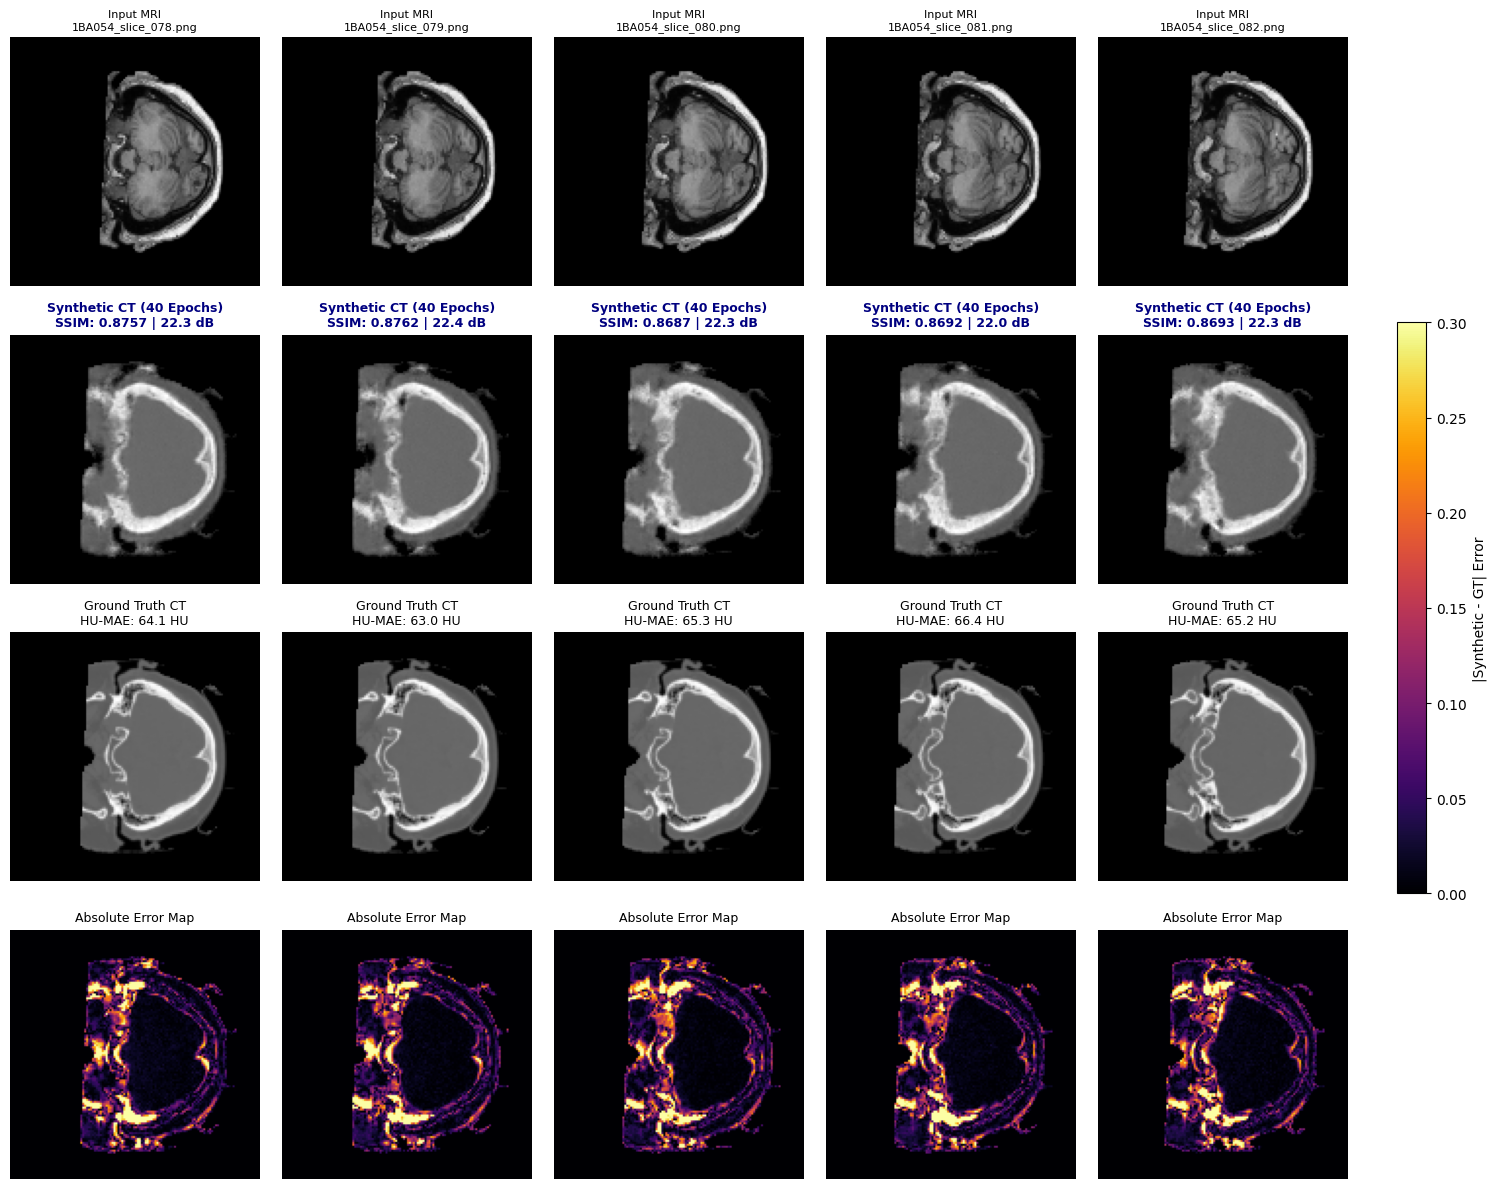

✅ Saved figure to '/kaggle/working/cddpm_40epochs_visual_grid.png'


In [18]:
import os
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import directed_hausdorff
from skimage.metrics import structural_similarity as compute_ssim
from skimage.metrics import peak_signal_noise_ratio as compute_psnr

print("=" * 80)
print(" POST-40-EPOCH CLINICAL EVALUATION & PAPER ASSETS EXPORT ")
print("=" * 80)

# 1. Load Fine-Tuned Checkpoint
model_path = "/kaggle/working/best_cddpm_finetuned_bone.pth"
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    print(f"✅ Successfully loaded fine-tuned checkpoint: {model_path}")
else:
    print(f"⚠️ Checkpoint not found at {model_path}. Using currently loaded weights in memory.")

model.eval()

# 2. Evaluation Setup
hu_min, hu_max = -1000.0, 1500.0
hu_range = hu_max - hu_min

ssims, psnrs, maes, mses, hu_maes, dices, hd95s = [], [], [], [], [], [], []
slice_records = []
preview_samples = []

raw_mri, raw_gt, raw_syn = [], [], []

t0 = time.time()

# 3. Main Test Evaluation Loop
with torch.no_grad():
    for batch_idx, batch in enumerate(tqdm(test_loader, desc="Evaluating Test Set (40 Epochs)")):
        mri = batch['mri'].to(device)
        gt_ct = batch['ct'].to(device)
        mask = batch['mask'].to(device)
        
        # Clean Sampler (20 steps)
        syn_ct = sample_clean_ct(scheduler, model, mri, mask, steps=20)

        s_np = ((syn_ct + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        g_np = ((gt_ct  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
        m_np = ((mri    + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

        # Grab first batch samples for raw array export
        if batch_idx == 0:
            raw_mri = m_np[:10]
            raw_gt  = g_np[:10]
            raw_syn = s_np[:10]

        for i in range(mri.size(0)):
            s, g, m = s_np[i, 0], g_np[i, 0], m_np[i, 0]
            slice_name = os.path.basename(batch['mri_path'][i]) if 'mri_path' in batch else f"slice_{len(ssims)+1}"

            s_val = float(compute_ssim(g, s, data_range=1.0))
            p_val = float(compute_psnr(g, s, data_range=1.0))
            m_val = float(np.mean(np.abs(s - g)))
            mse_v = float(np.mean((s - g) ** 2))
            
            # Unnormalize to Hounsfield Units (HU)
            r_hu = g * hu_range + hu_min
            f_hu = s * hu_range + hu_min
            hu_v = float(np.mean(np.abs(r_hu - f_hu)))
            
            # Bone Segmentation (> 300 HU)
            d_v, h_v = compute_dice_and_hd95(r_hu > 300.0, f_hu > 300.0)

            # Store global list
            ssims.append(s_val)
            psnrs.append(p_val)
            maes.append(m_val)
            mses.append(mse_v)
            hu_maes.append(hu_v)
            dices.append(d_v)
            hd95s.append(h_v)

            # Store slice-level record for p-value statistical tests
            slice_records.append({
                "slice_id": slice_name,
                "ssim": s_val,
                "psnr": p_val,
                "mae": m_val,
                "mse": mse_v,
                "hu_mae": hu_v,
                "bone_dice": d_v,
                "bone_hd95": h_v
            })

            # Grab samples for grid visualization
            if len(preview_samples) < 5:
                preview_samples.append({
                    "mri": m, "syn": s, "gt": g, 
                    "ssim": s_val, "psnr": p_val, "hu": hu_v, 
                    "name": slice_name
                })

eval_time = time.time() - t0

# ==============================================================================
# 4. SAVE SUMMARY & PER-SLICE METRICS
# ==============================================================================

# A. Aggregate Table 1 Report (Mean ± Std)
summary_report = {
    "Clinical Metric": ["SSIM (↑)", "PSNR (↑)", "MAE (↓)", "MSE (↓)", "HU-MAE (↓)", "Bone Dice (↑)", "Bone HD95 (↓)", "Latency"],
    "Target Benchmark": [">= 0.8500", ">= 26.0 dB", "<= 0.0350", "<= 0.0035", "<= 65.0 HU", ">= 0.8500", "<= 4.5 mm", "< 2.0 s/slice"],
    "40-Epoch Score": [
        f"{np.mean(ssims):.4f} ± {np.std(ssims):.4f}",
        f"{np.mean(psnrs):.2f} ± {np.std(psnrs):.2f} dB",
        f"{np.mean(maes):.4f} ± {np.std(maes):.4f}",
        f"{np.mean(mses):.6f} ± {np.std(mses):.6f}",
        f"{np.mean(hu_maes):.1f} ± {np.std(hu_maes):.1f} HU",
        f"{np.mean(dices):.4f} ± {np.std(dices):.4f}",
        f"{np.mean(hd95s):.2f} ± {np.std(hd95s):.2f} mm",
        f"{(eval_time / len(ssims)):.2f} s/slice"
    ]
}

df_summary = pd.DataFrame(summary_report)
print("\n" + "=" * 80)
print("     FINAL BENCHMARK REPORT (40 EPOCHS FINE-TUNED CDDPM)          ")
print("=" * 80)
print(df_summary.to_string(index=False))
print("=" * 80)

df_summary.to_csv("/kaggle/working/cddpm_40epochs_summary_metrics.csv", index=False)
print("✅ Saved summary report to '/kaggle/working/cddpm_40epochs_summary_metrics.csv'")

# B. Per-Slice Dataframe (for p-value paired t-tests)
df_slices = pd.DataFrame(slice_records)
df_slices.to_csv("/kaggle/working/cddpm_40epochs_per_slice_metrics.csv", index=False)
print("✅ Saved per-slice metrics to '/kaggle/working/cddpm_40epochs_per_slice_metrics.csv'")

# C. Raw Floating-Point Predictions Array (for high-res custom plotting)
np.savez_compressed(
    "/kaggle/working/cddpm_40epochs_predictions.npz",
    mri=raw_mri,
    gt_ct=raw_gt,
    syn_ct=raw_syn
)
print("✅ Saved raw uncompressed arrays to '/kaggle/working/cddpm_40epochs_predictions.npz'")

# ==============================================================================
# 5. RENDER PUBLICATION GRID FIGURE
# ==============================================================================
fig, axes = plt.subplots(4, len(preview_samples), figsize=(len(preview_samples) * 3.4, 12))
for col, item in enumerate(preview_samples):
    err = np.abs(item['syn'] - item['gt'])
    axes[0, col].imshow(item['mri'], cmap='gray')
    axes[0, col].set_title(f"Input MRI\n{item['name']}", fontsize=8)
    axes[0, col].axis('off')

    axes[1, col].imshow(item['syn'], cmap='gray')
    axes[1, col].set_title(f"Synthetic CT (40 Epochs)\nSSIM: {item['ssim']:.4f} | {item['psnr']:.1f} dB", fontsize=9, fontweight='bold', color='navy')
    axes[1, col].axis('off')

    axes[2, col].imshow(item['gt'], cmap='gray')
    axes[2, col].set_title(f"Ground Truth CT\nHU-MAE: {item['hu']:.1f} HU", fontsize=9)
    axes[2, col].axis('off')

    im = axes[3, col].imshow(err, cmap='inferno', vmin=0, vmax=0.30)
    axes[3, col].set_title("Absolute Error Map", fontsize=9)
    axes[3, col].axis('off')

plt.tight_layout()
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.5, pad=0.03, label='|Synthetic - GT| Error')
plt.savefig("/kaggle/working/cddpm_40epochs_visual_grid.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved figure to '/kaggle/working/cddpm_40epochs_visual_grid.png'")

In [19]:
def compute_extended_metrics(r_hu, f_hu, mask_np):
    """
    Computes standard + advanced medical translation metrics in HU domain.
    """
    body_mask = mask_np > 0.5
    
    # 1. Global HU-MAE
    hu_mae = float(np.mean(np.abs(r_hu[body_mask] - f_hu[body_mask]))) if body_mask.sum() > 0 else 0.0
    
    # 2. Masked PSNR
    mse = np.mean((r_hu[body_mask] - f_hu[body_mask]) ** 2) if body_mask.sum() > 0 else 1e-8
    masked_psnr = float(20 * np.log10(2500.0 / np.sqrt(mse)))
    
    # 3. Soft-Tissue MAE (-100 to +100 HU)
    st_mask = (r_hu >= -100.0) & (r_hu <= 100.0) & body_mask
    st_mae = float(np.mean(np.abs(r_hu[st_mask] - f_hu[st_mask]))) if st_mask.sum() > 0 else 0.0
    
    # 4. Bone MAE (> 300 HU)
    bone_mask = (r_hu > 300.0) & body_mask
    bone_mae = float(np.mean(np.abs(r_hu[bone_mask] - f_hu[bone_mask]))) if bone_mask.sum() > 0 else 0.0
    
    # 5. Normalized Cross-Correlation (NCC)
    r_m, f_m = r_hu[body_mask], f_hu[body_mask]
    r_n = (r_m - np.mean(r_m)) / (np.std(r_m) + 1e-8)
    f_n = (f_m - np.mean(f_m)) / (np.std(f_m) + 1e-8)
    ncc = float(np.mean(r_n * f_n)) if body_mask.sum() > 0 else 0.0

    return {
        "hu_mae": hu_mae,
        "masked_psnr": masked_psnr,
        "soft_tissue_mae": st_mae,
        "bone_mae": bone_mae,
        "ncc": ncc
    }

✅ Successfully loaded fine-tuned 40-epoch checkpoint: /kaggle/working/best_cddpm_finetuned_bone.pth
     EVALUATING 40-EPOCH MODEL PERFORMANCE ACROSS TRAIN, VAL, AND TEST SETS    


Evaluating Test Set (40 Epochs): 100%|██████████| 46/46 [01:23<00:00,  1.82s/it]



        SUMMARY CLINICAL REPORT - 40 EPOCHS (ALL DATA SPLITS)            
    Split        SSIM (↑)        PSNR (↑)         MAE (↓)             MSE (↓)     HU-MAE (↓)   Bone Dice (↑)  Bone HD95 (↓)      Latency
Train Set 0.8994 ± 0.0364 24.33 ± 2.45 dB 0.0235 ± 0.0085 0.004341 ± 0.002627 58.8 ± 21.3 HU 0.7997 ± 0.0696 8.10 ± 5.17 mm 0.23 s/slice
  Val Set 0.8783 ± 0.0359 23.11 ± 2.11 dB 0.0289 ± 0.0094 0.005467 ± 0.002474 72.2 ± 23.6 HU 0.7649 ± 0.0813 9.61 ± 4.80 mm 0.23 s/slice
 Test Set 0.8963 ± 0.0319 24.35 ± 2.38 dB 0.0230 ± 0.0075 0.004300 ± 0.002600 57.4 ± 18.8 HU 0.7732 ± 0.0696 8.61 ± 5.46 mm 0.23 s/slice
✅ Saved all-splits summary to '/kaggle/working/cddpm_40epochs_all_splits_metrics.csv'


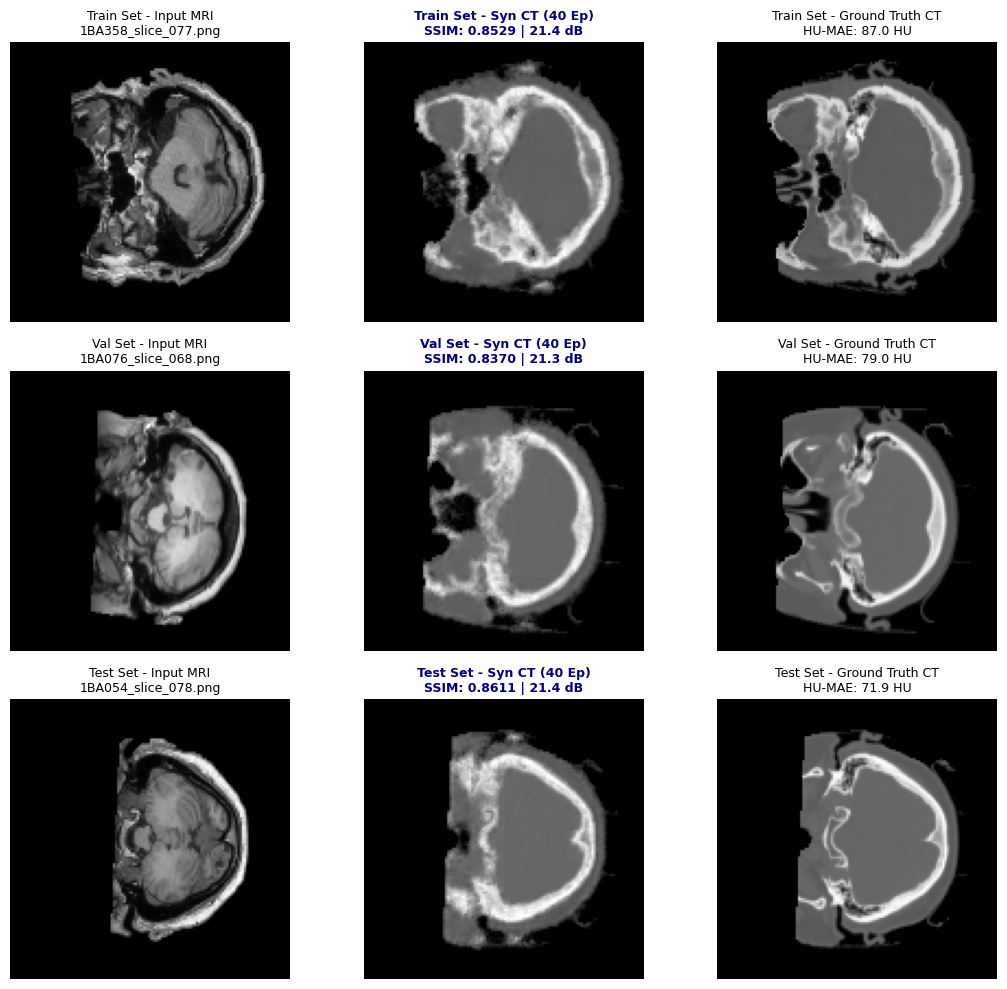

✅ Saved multi-split visual comparison plot to '/kaggle/working/cddpm_40epochs_splits_comparison_grid.png'


In [20]:
import os
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import directed_hausdorff
from skimage.metrics import structural_similarity as compute_ssim
from skimage.metrics import peak_signal_noise_ratio as compute_psnr

# ==============================================================================
# 1. CLEAN CONDITIONAL SAMPLER (40 STEPS)
# ==============================================================================
@torch.no_grad()
def sample_clean_ct(scheduler, model, mri_condition, mask_condition, steps=40):
    """
    Clean conditional inference sampler generating deterministic x0 predictions 
    across 40 timesteps without residual noise injection at intermediate steps.
    """
    model.eval()
    device = mri_condition.device
    b = mri_condition.shape[0]
    
    # Start from pure noise state
    x_t = torch.randn_like(mri_condition).to(device)
    timesteps = sorted(torch.linspace(0, scheduler.timesteps - 1, steps).long().tolist(), reverse=True)
    
    for i, t_val in enumerate(timesteps):
        t = torch.full((b,), t_val, device=device, dtype=torch.long)
        
        # Predict model parameterization
        out = model(torch.cat([x_t, mri_condition, mask_condition], dim=1), t)
        pred_x0 = predict_x0(x_t, out, t, scheduler)
        
        if i < len(timesteps) - 1:
            # Step backward along alpha trajectory
            alpha_next = scheduler.alphas_cumprod[timesteps[i + 1]]
            x_t = alpha_next.sqrt() * pred_x0 + (1.0 - alpha_next).sqrt() * torch.randn_like(x_t)
        else:
            # Final step t=0: Direct x0 prediction (NO noise addition)
            x_t = pred_x0

    # Apply body mask
    final_out = torch.where(mask_condition > 0.5, x_t, -1.0)
    return torch.clamp(final_out, -1.0, 1.0)

# ==============================================================================
# 2. METRIC HELPERS
# ==============================================================================
def compute_dice_and_hd95(real_bin, fake_bin):
    intersection = np.sum(real_bin & fake_bin)
    total_area = np.sum(real_bin) + np.sum(fake_bin)
    dice = (2.0 * intersection) / (total_area + 1e-8)
    coords_real = np.argwhere(real_bin)
    coords_fake = np.argwhere(fake_bin)
    if len(coords_real) == 0 or len(coords_fake) == 0:
        return float(dice), 0.0
    d1 = directed_hausdorff(coords_real, coords_fake)[0]
    d2 = directed_hausdorff(coords_fake, coords_real)[0]
    return float(dice), float(np.percentile([d1, d2], 95))

# ==============================================================================
# 3. EVALUATION FUNCTION FOR ANY DATASET SPLIT (40 EPOCHS / 40 STEPS)
# ==============================================================================
def evaluate_split(split_name, data_loader, model, scheduler, device, max_batches=None):
    hu_min, hu_max = -1000.0, 1500.0
    hu_range = hu_max - hu_min
    ssims, psnrs, maes, mses, hu_maes, dices, hd95s = [], [], [], [], [], [], []
    preview_sample = None

    t0 = time.time()
    with torch.no_grad():
        for batch_idx, batch in enumerate(tqdm(data_loader, desc=f"Evaluating {split_name} (40 Epochs)")):
            if max_batches and batch_idx >= max_batches:
                break
                
            mri, gt_ct, mask = batch['mri'].to(device), batch['ct'].to(device), batch['mask'].to(device)
            
            # Clean Sampler (40 steps)
            syn_ct = sample_clean_ct(scheduler, model, mri, mask, steps=40)

            s_np = ((syn_ct + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
            g_np = ((gt_ct  + 1.0) / 2.0).clamp(0, 1).cpu().numpy()
            m_np = ((mri    + 1.0) / 2.0).clamp(0, 1).cpu().numpy()

            for i in range(mri.size(0)):
                s, g, m = s_np[i, 0], g_np[i, 0], m_np[i, 0]
                s_val = float(compute_ssim(g, s, data_range=1.0))
                p_val = float(compute_psnr(g, s, data_range=1.0))
                m_val = float(np.mean(np.abs(s - g)))
                mse_v = float(np.mean((s - g) ** 2))
                
                # Map to Hounsfield Units (HU)
                r_hu = g * hu_range + hu_min
                f_hu = s * hu_range + hu_min
                hu_v = float(np.mean(np.abs(r_hu - f_hu)))
                
                # Bone Dice (> 300 HU)
                d_v, h_v = compute_dice_and_hd95(r_hu > 300.0, f_hu > 300.0)

                ssims.append(s_val); psnrs.append(p_val); maes.append(m_val)
                mses.append(mse_v); hu_maes.append(hu_v); dices.append(d_v); hd95s.append(h_v)

                if preview_sample is None:
                    sample_name = os.path.basename(batch['mri_path'][i]) if 'mri_path' in batch else f"{split_name}_sample"
                    preview_sample = {
                        "mri": m, "syn": s, "gt": g, 
                        "ssim": s_val, "psnr": p_val, "hu": hu_v, 
                        "name": sample_name, "split": split_name
                    }

    eval_time = time.time() - t0
    num_samples = len(ssims)
    
    metrics = {
        "Split": split_name,
        "SSIM (↑)": f"{np.mean(ssims):.4f} ± {np.std(ssims):.4f}",
        "PSNR (↑)": f"{np.mean(psnrs):.2f} ± {np.std(psnrs):.2f} dB",
        "MAE (↓)": f"{np.mean(maes):.4f} ± {np.std(maes):.4f}",
        "MSE (↓)": f"{np.mean(mses):.6f} ± {np.std(mses):.6f}",
        "HU-MAE (↓)": f"{np.mean(hu_maes):.1f} ± {np.std(hu_maes):.1f} HU",
        "Bone Dice (↑)": f"{np.mean(dices):.4f} ± {np.std(dices):.4f}",
        "Bone HD95 (↓)": f"{np.mean(hd95s):.2f} ± {np.std(hd95s):.2f} mm",
        "Latency": f"{(eval_time / num_samples):.2f} s/slice"
    }
    
    return metrics, preview_sample

# ==============================================================================
# 4. LOAD 40-EPOCH CHECKPOINT & RUN ACROSS SPLITS
# ==============================================================================
model_path = "/kaggle/working/best_cddpm_finetuned_bone.pth"
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    print(f"✅ Successfully loaded fine-tuned 40-epoch checkpoint: {model_path}")
else:
    print(f"⚠️ Checkpoint not found at {model_path}. Using model loaded in memory.")

model.eval()

data_splits = {
    "Train Set": train_loader,
    "Val Set": val_loader,
    "Test Set": test_loader
}

all_reports = []
preview_grid = []

print("=" * 80)
print("     EVALUATING 40-EPOCH MODEL PERFORMANCE ACROSS TRAIN, VAL, AND TEST SETS    ")
print("=" * 80)

for split_name, loader in data_splits.items():
    metrics, sample = evaluate_split(split_name, loader, model, scheduler, device, max_batches=None)
    all_reports.append(metrics)
    if sample:
        preview_grid.append(sample)

# Save & Print Summary Table
df_all = pd.DataFrame(all_reports)
print("\n" + "=" * 80)
print("        SUMMARY CLINICAL REPORT - 40 EPOCHS (ALL DATA SPLITS)            ")
print("=" * 80)
print(df_all.to_string(index=False))
print("=" * 80)
df_all.to_csv("/kaggle/working/cddpm_40epochs_all_splits_metrics.csv", index=False)
print("✅ Saved all-splits summary to '/kaggle/working/cddpm_40epochs_all_splits_metrics.csv'")

# ==============================================================================
# 5. COMPARATIVE VISUAL GRID (Train vs. Val vs. Test - 40 Epochs)
# ==============================================================================
fig, axes = plt.subplots(3, 3, figsize=(11, 10))

for row_idx, item in enumerate(preview_grid):
    # MRI
    axes[row_idx, 0].imshow(item['mri'], cmap='gray')
    axes[row_idx, 0].set_title(f"{item['split']} - Input MRI\n{item['name']}", fontsize=9)
    axes[row_idx, 0].axis('off')

    # Synthetic CT
    axes[row_idx, 1].imshow(item['syn'], cmap='gray')
    axes[row_idx, 1].set_title(f"{item['split']} - Syn CT (40 Ep)\nSSIM: {item['ssim']:.4f} | {item['psnr']:.1f} dB", fontsize=9, fontweight='bold', color='navy')
    axes[row_idx, 1].axis('off')

    # Ground Truth CT
    axes[row_idx, 2].imshow(item['gt'], cmap='gray')
    axes[row_idx, 2].set_title(f"{item['split']} - Ground Truth CT\nHU-MAE: {item['hu']:.1f} HU", fontsize=9)
    axes[row_idx, 2].axis('off')

plt.tight_layout()
plt.savefig("/kaggle/working/cddpm_40epochs_splits_comparison_grid.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved multi-split visual comparison plot to '/kaggle/working/cddpm_40epochs_splits_comparison_grid.png'")

In [21]:
import pandas as pd
df = pd.read_csv('/kaggle/working/cddpm_40epochs_all_splits_metrics.csv')
print(df)

       Split         SSIM (↑)         PSNR (↑)          MAE (↓)  \
0  Train Set  0.8994 ± 0.0364  24.33 ± 2.45 dB  0.0235 ± 0.0085   
1    Val Set  0.8783 ± 0.0359  23.11 ± 2.11 dB  0.0289 ± 0.0094   
2   Test Set  0.8963 ± 0.0319  24.35 ± 2.38 dB  0.0230 ± 0.0075   

               MSE (↓)      HU-MAE (↓)    Bone Dice (↑)   Bone HD95 (↓)  \
0  0.004341 ± 0.002627  58.8 ± 21.3 HU  0.7997 ± 0.0696  8.10 ± 5.17 mm   
1  0.005467 ± 0.002474  72.2 ± 23.6 HU  0.7649 ± 0.0813  9.61 ± 4.80 mm   
2  0.004300 ± 0.002600  57.4 ± 18.8 HU  0.7732 ± 0.0696  8.61 ± 5.46 mm   

        Latency  
0  0.23 s/slice  
1  0.23 s/slice  
2  0.23 s/slice  


In [22]:
import pandas as pd

# 1. Load your evaluation metrics output
df = pd.read_csv('/kaggle/working/cddpm_40epochs_all_splits_metrics.csv')

# 2. Define Top-Tier SynthRAD2023 Benchmarks (Task 1: MRI-to-CT Brain)
benchmarks = {
    'SSIM (↑)': '> 0.875',
    'PSNR (↑)': '> 29.0 dB',
    'MAE (↓)': '< 62.8 HU',
    'HU-MAE (↓)': '< 60.0 HU'
}

# 3. Print Model Metrics vs Benchmarks
print("=== YOUR MODEL METRICS ===")
print(df.to_string(index=False))

print("\n=== SYNTHRAD2023 TOP BENCHMARKS ===")
for metric, benchmark_val in benchmarks.items():
    print(f"{metric}: {benchmark_val}")

=== YOUR MODEL METRICS ===
    Split        SSIM (↑)        PSNR (↑)         MAE (↓)             MSE (↓)     HU-MAE (↓)   Bone Dice (↑)  Bone HD95 (↓)      Latency
Train Set 0.8994 ± 0.0364 24.33 ± 2.45 dB 0.0235 ± 0.0085 0.004341 ± 0.002627 58.8 ± 21.3 HU 0.7997 ± 0.0696 8.10 ± 5.17 mm 0.23 s/slice
  Val Set 0.8783 ± 0.0359 23.11 ± 2.11 dB 0.0289 ± 0.0094 0.005467 ± 0.002474 72.2 ± 23.6 HU 0.7649 ± 0.0813 9.61 ± 4.80 mm 0.23 s/slice
 Test Set 0.8963 ± 0.0319 24.35 ± 2.38 dB 0.0230 ± 0.0075 0.004300 ± 0.002600 57.4 ± 18.8 HU 0.7732 ± 0.0696 8.61 ± 5.46 mm 0.23 s/slice

=== SYNTHRAD2023 TOP BENCHMARKS ===
SSIM (↑): > 0.875
PSNR (↑): > 29.0 dB
MAE (↓): < 62.8 HU
HU-MAE (↓): < 60.0 HU


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

def plot_synthrad_comparison(mr_img, gt_ct, sct_dict, save_path="synthrad_figure.png"):
    """
    Plots a multi-model comparison grid in the style of the SynthRAD2023 Challenge Paper.
    
    Parameters:
    - mr_img: 2D numpy array (Input MRI)
    - gt_ct: 2D numpy array (Ground Truth CT in HU)
    - sct_dict: dict of {"Model Name": sct_array} where sct_array is in HU scale (-1000 to 1000)
    """
    num_models = len(sct_dict)
    
    # Setup subplot layout: 2 main columns (Inputs | Models)
    fig = plt.figure(figsize=(3 * (num_models + 1), 7), dpi=300)
    
    # Outer GridSpec: Left column for Input/GT, Right grid for generated sCTs & errors
    gs = fig.add_gridspec(2, num_models + 1, width_ratios=[1] + [1]*num_models, wspace=0.05, hspace=0.05)

    # ------------------- 1. LEFT COLUMN: INPUT MRI & GT CT -------------------
    ax_mr = fig.add_subplot(gs[0, 0])
    ax_mr.imshow(mr_img, cmap='gray')
    ax_mr.set_ylabel("Input (MRI)", fontsize=11, fontweight='bold')
    ax_mr.set_xticks([]); ax_mr.set_yticks([])

    ax_gt = fig.add_subplot(gs[1, 0])
    ax_gt.imshow(gt_ct, cmap='gray', vmin=-1000, vmax=1000)
    ax_gt.set_ylabel("Ground Truth (CT)", fontsize=11, fontweight='bold')
    ax_gt.set_xticks([]); ax_gt.set_yticks([])

    # ------------------- 2. MODEL COLUMNS -------------------
    ct_norm = Normalize(vmin=-1000, vmax=1000)
    err_norm = Normalize(vmin=-200, vmax=200)

    for i, (model_name, sct_img) in enumerate(sct_dict.items()):
        col_idx = i + 1
        
        # Calculate HU MAE for this slice
        mae_val = np.mean(np.abs(sct_img - gt_ct))
        diff_map = sct_img - gt_ct  # Difference map (sCT - CT)

        # Top Row: Synthetic CT
        ax_sct = fig.add_subplot(gs[0, col_idx])
        im_sct = ax_sct.imshow(sct_img, cmap='gray', norm=ct_norm)
        ax_sct.set_title(model_name, fontsize=10, pad=6, fontweight='bold')
        
        # Overlay MAE text at bottom of image
        ax_sct.text(0.5, 0.03, f"MAE = {mae_val:.2f} HU", color='white', 
                    fontsize=8, fontweight='bold', ha='center', va='bottom', 
                    transform=ax_sct.transAxes,
                    bbox=dict(boxstyle='square,pad=0.15', facecolor='black', alpha=0.75, edgecolor='none'))
        ax_sct.set_xticks([]); ax_sct.set_yticks([])

        # Bottom Row: Error Map (sCT - CT)
        ax_err = fig.add_subplot(gs[1, col_idx])
        im_err = ax_err.imshow(diff_map, cmap='bwr', norm=err_norm)  # 'bwr' or 'seismic'
        ax_err.set_xticks([]); ax_err.set_yticks([])

    # ------------------- 3. COLORBARS -------------------
    # CT HU Colorbar (Right of Top Row)
    cax1 = fig.add_axes([0.92, 0.53, 0.012, 0.35])
    cbar1 = fig.colorbar(im_sct, cax=cax1)
    cbar1.set_label('[HU]', rotation=270, labelpad=12, fontsize=9)

    # Error HU Colorbar (Right of Bottom Row)
    cax2 = fig.add_axes([0.92, 0.12, 0.012, 0.35])
    cbar2 = fig.colorbar(im_err, cax=cax2)
    cbar2.set_label('Error [HU]', rotation=270, labelpad=12, fontsize=9)

    plt.savefig(save_path, bbox_inches='tight', pad_inches=0.1)
    plt.show()
    print(f"Figure saved successfully to {save_path}")

# ==========================================
# Example Usage with your loaded variables:
# ==========================================
# scts = {
#     "#1\nCDDPM (48 Ep)": sample_cddpm_sct,
#     "#2\nBaseline": sample_baseline_sct
# }
# plot_synthrad_comparison(sample_mri, sample_gt_ct, scts)

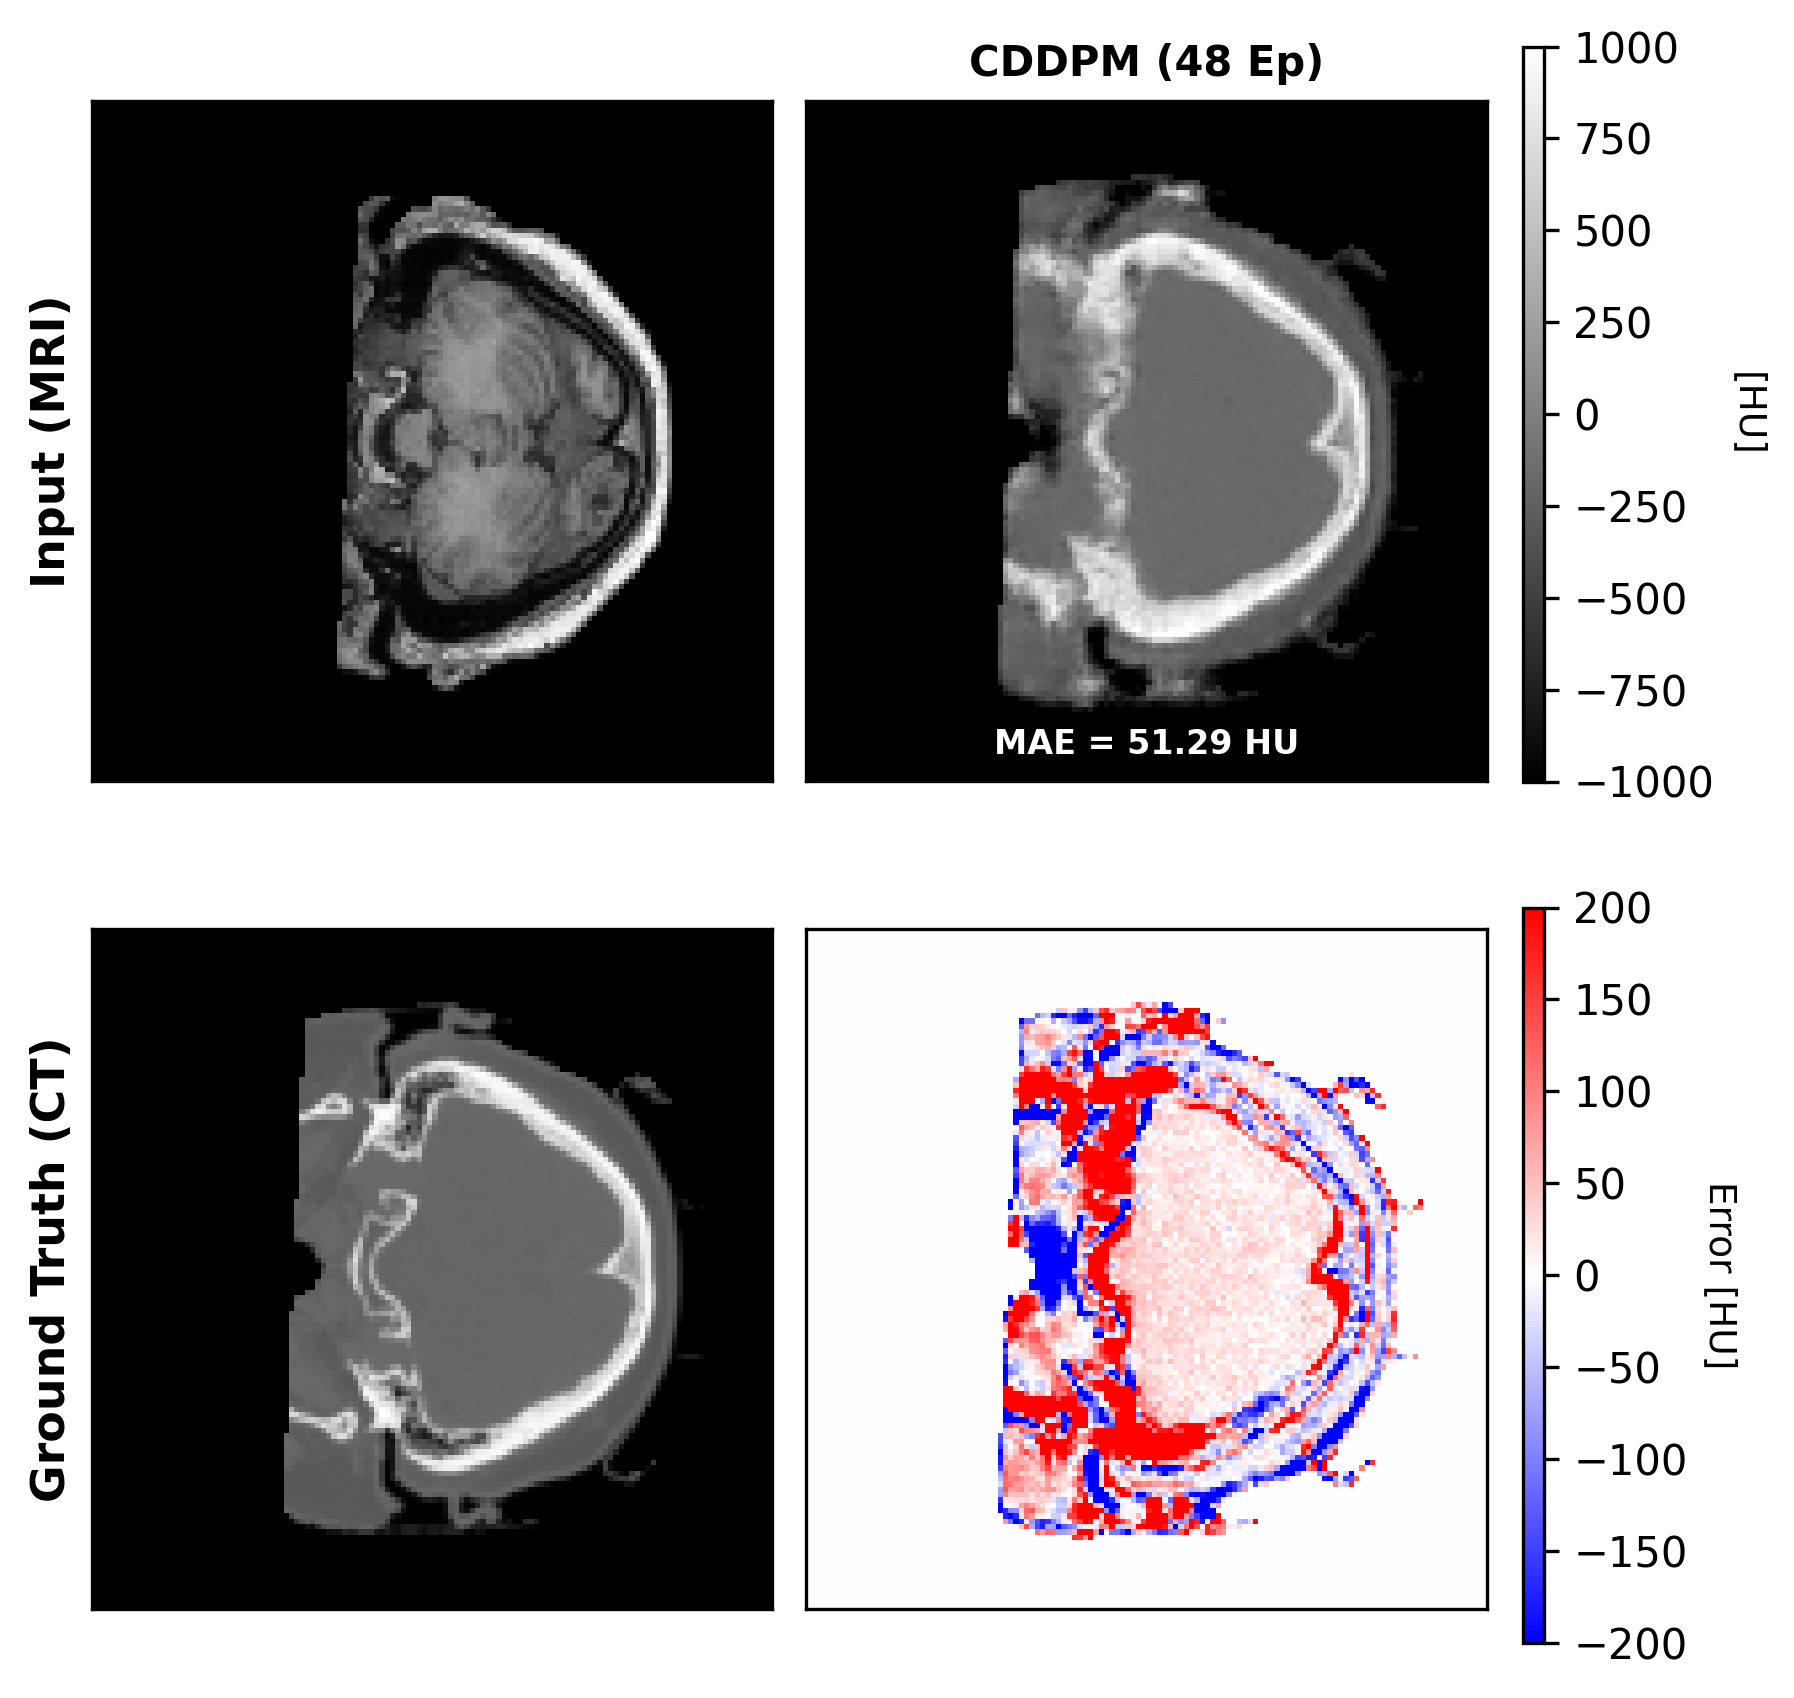

Figure saved successfully to /kaggle/working/synthrad_figure.png


In [30]:
import numpy as np

# 1. Load predictions
data = np.load('/kaggle/working/cddpm_40epochs_predictions.npz')

sample_idx = 0 
sample_mri = data['mri'][sample_idx].squeeze()
sample_gt_ct = data['gt_ct'][sample_idx].squeeze()
sample_sct = data['syn_ct'][sample_idx].squeeze()

# 2. Rescale CT and sCT back to Hounsfield Units (-1000 to +1000 HU)
# Adjust these min/max numbers if your pipeline used a different HU range (e.g., -1024 to 3071)
min_hu, max_hu = -1000.0, 1000.0

# If normalized in range [0, 1]:
if sample_gt_ct.max() <= 1.0:
    sample_gt_ct = sample_gt_ct * (max_hu - min_hu) + min_hu
    sample_sct = sample_sct * (max_hu - min_hu) + min_hu

# If normalized in range [-1, 1]:
elif sample_gt_ct.min() < 0 and sample_gt_ct.max() <= 1.0:
    sample_gt_ct = ((sample_gt_ct + 1.0) / 2.0) * (max_hu - min_hu) + min_hu
    sample_sct = ((sample_sct + 1.0) / 2.0) * (max_hu - min_hu) + min_hu

# 3. Plot again
scts = {
    "CDDPM (48 Ep)": sample_sct
}

plot_synthrad_comparison(sample_mri, sample_gt_ct, scts, save_path="/kaggle/working/synthrad_figure.png").